<a href="https://colab.research.google.com/github/LCaravaggio/Happiness_Polarization/blob/main/Event_Studies_Pool_Controles_y_FE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cargar de datos

In [1]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import re

BASE = "https://www.latinobarometro.org"
INDEX = f"{BASE}/agregados"

headers = {
    "User-Agent": "Mozilla/5.0"
}

# =========================
# 1. obtener páginas de cada ola
# =========================

html = requests.get(INDEX, headers=headers).text
soup = BeautifulSoup(html, "html.parser")

wave_pages = []

for a in soup.find_all("a", href=True):

    href = a["href"]

    # links tipo /latinobarometro-2023
    if re.search(r"latinobarometro-\d{4}$", href):

        full = urljoin(BASE, href)
        wave_pages.append(full)

wave_pages = sorted(set(wave_pages))

print("Olas encontradas:")
for w in wave_pages:
    print(w)

# =========================
# 2. entrar a cada ola y buscar ZIP de Stata
# =========================

stata_links = []

for page in wave_pages:

    print(f"\nRevisando {page}")

    try:
        html = requests.get(page, headers=headers, timeout=20).text
        soup = BeautifulSoup(html, "html.parser")

        for a in soup.find_all("a", href=True):

            href = a["href"]
            text = a.get_text(" ", strip=True).lower()

            full = urljoin(page, href)

            # queremos ZIPs relacionados con Stata
            if (
                ".zip" in href.lower()
                and (
                    "stata" in href.lower()
                    or "dta" in href.lower()
                    or "stata" in text
                )
            ):
                stata_links.append(full)

    except Exception as e:
        print("Error:", e)

# limpiar duplicados
stata_links = sorted(set(stata_links))

print("\nZIPs Stata encontrados:\n")

for l in stata_links:
    print(l)

Olas encontradas:
https://www.latinobarometro.org/latinobarometro-1995
https://www.latinobarometro.org/latinobarometro-1996
https://www.latinobarometro.org/latinobarometro-1997
https://www.latinobarometro.org/latinobarometro-1998
https://www.latinobarometro.org/latinobarometro-2000
https://www.latinobarometro.org/latinobarometro-2001
https://www.latinobarometro.org/latinobarometro-2002
https://www.latinobarometro.org/latinobarometro-2003
https://www.latinobarometro.org/latinobarometro-2004
https://www.latinobarometro.org/latinobarometro-2005
https://www.latinobarometro.org/latinobarometro-2006
https://www.latinobarometro.org/latinobarometro-2007
https://www.latinobarometro.org/latinobarometro-2008
https://www.latinobarometro.org/latinobarometro-2009
https://www.latinobarometro.org/latinobarometro-2010
https://www.latinobarometro.org/latinobarometro-2011
https://www.latinobarometro.org/latinobarometro-2013
https://www.latinobarometro.org/latinobarometro-2015
https://www.latinobarometro.

In [2]:
import requests

import shutil
import os

# borrar carpeta rota
shutil.rmtree("latinobarometro", ignore_errors=True)

# recrear
os.makedirs("latinobarometro", exist_ok=True)

for link in stata_links:

    filename = link.split("/")[-1]
    filepath = os.path.join("latinobarometro", filename)

    print("Descargando:", filename)

    r = requests.get(link)

    with open(filepath, "wb") as f:
        f.write(r.content)

Descargando: latinobarometro-1995-dta.zip
Descargando: latinobarometro-1996-dta.zip
Descargando: latinobarometro-1997-dta.zip
Descargando: latinobarometro-1998-dta.zip
Descargando: latinobarometro-2000-dta.zip
Descargando: latinobarometro-2001-dta.zip
Descargando: latinobarometro-2002-dta.zip
Descargando: latinobarometro-2003-dta.zip
Descargando: latinobarometro-2004-dta.zip
Descargando: latinobarometro-2005-dta.zip
Descargando: latinobarometro-2006-dta.zip
Descargando: latinobarometro-2007-dta.zip
Descargando: latinobarometro-2008-dta.zip
Descargando: latinobarometro-2009-dta.zip
Descargando: latinobarometro-2010-dta.zip
Descargando: latinobarometro-2011-dta.zip
Descargando: latinobarometro-2013-dta.zip
Descargando: latinobarometro-2015-dta.zip
Descargando: latinobarometro2016-dta.zip
Descargando: latinobarometro2017-dta.zip
Descargando: latinobarometro-2018-eng-stata-v20190303.zip
Descargando: latinobarometro-2018-esp-dta-v20190303.zip
Descargando: latinobarometro-2020-eng-stata-v1-0

In [3]:
!mkdir -p latinobarometro/unzipped

!find latinobarometro -name "*.zip" -exec unzip -o {} -d latinobarometro/unzipped \;

Archive:  latinobarometro/latinobarometro-2024-stata-v20250817.zip
  inflating: latinobarometro/unzipped/Latinobarometro_2024_Stata_eng_v20250817.dta  
  inflating: latinobarometro/unzipped/Latinobarometro_2024_Stata_esp_v20250817.dta  
  inflating: latinobarometro/unzipped/Latinobarometro_2024_Cuestionario_esp.pdf  
  inflating: latinobarometro/unzipped/Latinobarometro_2024_Cuestionario_eng.pdf  
Archive:  latinobarometro/latinobarometro-2004-dta.zip
  inflating: latinobarometro/unzipped/Latinobarometro_2004_Eng.pdf  
  inflating: latinobarometro/unzipped/Latinobarometro_2004_Esp.pdf  
  inflating: latinobarometro/unzipped/Latinobarometro_2004_datos_eng_v2014_06_27.dta  
  inflating: latinobarometro/unzipped/Latinobarometro_2004_datos_esp_v2014_06_27.dta  
Archive:  latinobarometro/latinobarometro2016-dta.zip
  inflating: latinobarometro/unzipped/Latinobarometro2016Eng_v20170205.dta  
  inflating: latinobarometro/unzipped/Latinobarometro2016EngQuestionnaire.docx  
  inflating: latinob

In [4]:
# =========================
# mapeo armonizado
# =========================

varmap = {

    # ---------------------------------
    # satisfacción con la vida
    # ---------------------------------

    "life_satisfaction": {

        1997: "nsp10",
        2000: "P8ST",
        2001: "p41st",
        2002: "p1wvs",
        2003: "p19st",
        2004: "p1st",
        2005: "p1st",
        2006: "p1st_a",
        2007: "p1st",
        2008: "p27st",
        2009: "p1st",
        2010: "P1ST",
        2011: "P1ST",
        2013: "P1ST",
        2015: "P1ST",
        2016: "P1ST",
        2017: "P1ST",
        2018: "P1STC",
        2020: "p1st",
        2023: "P1ST",
        2024: "P1ST"
    },


    # ---------------------------------
    # situación económica actual del país
    # ---------------------------------

    "econ_country": {

        1995: "p1",
        1996: "p1",
        1997: "sp1",
        1998: "sp1",
        2000: "P1ST",
        2001: "p1st",
        2002: "p2sta",
        2003: "p1st",
        2004: "p2st",
        2005: "p2st",
        2006: "p2st",
        2007: "p100st",
        2008: "p4st",
        2009: "p3st_a",
        2010: "P3ST_A",
        2011: "P3ST_A",
        2013: "P3STGBS",
        2015: "P3STGBS",
        2016: "P4STGBS",
        2017: "P4STGBSC",
        2018: "P6STGBSC",
        2020: "p4stgbs",
        2023: "P5STGBS",
        2024: "P6STGBS"
    },

    # ---------------------------------
    # confianza interpersonal
    # ---------------------------------

    "trust_people": {

        1996: "p12",
        1997: "sp21",
        1998: "sp20",
        2000: "P17ST",
        2001: "p42st",
        2002: "p29st",
        2003: "p20st",
        2004: "p43st",
        2005: "p14st",
        2006: "p45st",
        2007: "p23st",
        2008: "p21wvsst",
        2009: "p58st",
        2010: "P55ST",
        2011: "P25ST",
        2013: "P29STGBS",
        2015: "P15STGBS",
        2016: "P12STGBS",
        2017: "P13STGBS",
        2018: "P11STGBS",
        2020: "p9stgbs",
        2023: "P9STGBS",
        2024: "P10STGBS"
    },

    # ---------------------------------
    # ciudad
    # ---------------------------------

    "city": {
        1997: "ciudad",
        2000: "ciudad",
        2001: "ciudad",
        2003: "ciudad",
        2004: "Ciudad",
        2005: "ciudad",
        2006: "ciudad",
        2007: "ciudad",
        2008: "ciudad",
        2009: "ciudad",
        2010: "ciudad",
        2011: "ciudad",
        2013: "ciudad",
        2015: "ciudad",
        2016: "ciudad",
        2017: "ciudad",
        2018: "CIUDAD",
        2020: "ciudad",
        2023: "ciudad",
        2024: "CIUDAD"
    },

    # ---------------------------------
    # interés en política
    # ---------------------------------

    "interest_politics": {

        1995: "p62",
        1996: "p64",
        1997: "sp41",
        1998: "sp36",
        2000: "P63ST",
        2001: "p56st",
        2003: "p61st",
        2004: "p29st",
        2005: "p37st",
        2007: "p59st",
        2009: "p32st",
        2010: "P23ST",
        2013: "P20STGBS",
        2020: "p46stgbs",
        2023: "P40STGBS",
        2024: "P36STGBS",

    },

    # ---------------------------------
    # sexo
    # ---------------------------------

    "sex": {

        1995: "s1",
        1996: "s1",
        1997: "s1",
        1998: "s1",
        2000: "S1",
        2001: "s1",
        2002: "s1",
        2003: "s1",
        2004: "s1",
        2005: "s6",
        2006: "s6",
        2007: "s10",
        2008: "s8",
        2009: "s5",
        2010: "S7",
        2011: "S16",
        2013: "S10",
        2015: "S12",
        2016: "sexo",
        2017: "sexo",
        2018: "SEXO",
        2020: "sexo",
        2023: "sexo",
        2024: "SEXO"
    },

    # ---------------------------------
    # edad
    # ---------------------------------

    "age": {

        1995: "s2",
        1996: "s2",
        1997: "s2",
        1998: "s2",
        2000: "S2",
        2001: "s2",
        2002: "s2",
        2003: "s2",
        2004: "s2",
        2005: "s7",
        2006: "s7",
        2007: "s11",
        2008: "s9",
        2009: "s6",
        2010: "S8",
        2011: "S17",
        2013: "S11",
        2015: "S13",
        2016: "edad",
        2017: "edad",
        2018: "EDAD",
        2020: "edad",
        2023: "edad",
        2024: "EDAD"
    },

    # ---------------------------------
    # estado civil
    # ---------------------------------

    "civil_status": {

        1995: "s6",
        1996: "s5",
        1997: "s5",
        1998: "s5",
        2000: "S4",
        2001: "s4",
        2002: "s4",
        2003: "s4",
        2004: "s4",
        2005: "s9",
        2006: "s9",
        2007: "s13",
        2008: "s3",
        2009: "s3",
        2010: "S5",
        2011: "S15",
        2013: "S9",
        2015: "S11",
        2016: "S5",
        2017: "S6",
        2018: "S23"
    },

    # ---------------------------------
    # izquierda-derecha
    # ---------------------------------

    "left_right": {

        1995: "p31",
        1996: "p38",
        1997: "sp56",
        1998: "sp52",
        2000: "P52ST",
        2001: "p54st",
        2002: "p64st",
        2003: "p60st",
        2004: "p87st",
        2005: "p34st",
        2006: "p47st",
        2007: "p67st",
        2008: "p56st",
        2009: "p69st",
        2010: "P60ST",
        2011: "P76ST",
        2013: "P41ST",
        2015: "P27ST",
        2016: "P17ST",
        2017: "P19STC",
        2018: "P22ST",
        2020: "p18st",
        2023: "P16ST",
        2024: "P16ST"
    },


    # ---------------------------------
    # país
    # ---------------------------------

    "country": {

        1995: "pais",
        1996: "pais",
        1997: "idenpa",
        1998: "idenpa",
        2000: "idenpa",
        2001: "idenpa",
        2002: "idenpa",
        2003: "idenpa",
        2004: "idenpa",
        2005: "idenpa",
        2006: "idenpa",
        2007: "idenpa",
        2008: "idenpa",
        2009: "idenpa",
        2010: "idenpa",
        2011: "idenpa",
        2013: "idenpa",
        2015: "idenpa",
        2016: "idenpa",
        2017: "idenpa",
        2018: "IDENPA",
        2020: "idenpa",
        2023: "idenpa",
        2024: "IDENPA"
    },

    # ---------------------------------
    # educación
    # ---------------------------------

"education": {

    1995: "s17",
    1996: "s14",
    1997: "s10",
    1998: "s11",
    2000: "S6",
    2001: "s6",
    2002: "s6",
    2003: "s6",
    2004: "s6",
    2005: "s11",
    2006: "s11",
    2007: "s15",
    2008: "s15",
    2009: "s12",
    2010: "S14",
    2011: "S21",
    2013: "S17",
    2015: "S19",
    2016: "S13",
    2017: "S14",
    2018: "S10",
    2020: "s16",
    2023: "S11",
    2024: "S11"
},

# ---------------------------------
# twitter
# ---------------------------------

"twitter": {

    2009: "S25_E",
    2010: "S27_E",
    2011: "S33ST_BE",
    2013: "P83TNCE",
    2015: "S10M_E",
    2016: "S15M_D",
    2017: "S16M_D",
    2018: "S12M.D",
    2020: "s19m_04",
    2023: "S14M_D",
    2024: "S14M.4"

},

# ---------------------------------
# Voto
# ---------------------------------
"vote": {

    1995: "p33",
    1996: "p40",
    1997: "sp58",
    1998: "sp53",
    2000: "P54ST",
    2001: "p55st",
    2002: "p45st",
    2003: "p54st",
    2004: "p30st",
    2005: "p48st",
    2006: "p38st",
    2007: "p64st",
    2008: "p61st",
    2009: "p35st",
    2010: "P29ST",
    2011: "P38ST",
    2013: "P22TGBSM",
    2015: "P23TGBSM",
    2016: "P15STGBS",
    2017: "P16STGBS",
    2018: "P21STGBS.A",
    2020: "P50STGBS_A",
    2023: "P43STGBS_A",
    2024: "P39STGBS.A"
},

# ---------------------------------
# Confianza en el Congreso
# ---------------------------------

"confianza_congreso": {
    1995: "p27i",
    1996: "p33i",
    1997: "sp63f",
    1998: "sp38f",
    2000: "P35ST_F",
    2001: "p61stf",
    2002: "p36std",
    2003: "p21stf",
    2004: "p34stf",
    2005: "p45sta",
    2006: "p24st_f",
    2007: "p24st_f",
    2008: "p28st_a",
    2009: "p26st_a",
    2010: "P20ST_A",
    2011: "P22ST_A",
    2013: "P26TGB_C",
    2015: "P16ST_F",
    2016: "P13STD",
    2017: "P14ST_D",
    2018: "P15STGBSC.D",
    2020: "p13st_d",
    2023: "P13ST_D",
    2024: "P14ST.D"
},

# ---------------------------------
# Confianza en el Gobierno
# ---------------------------------

"confianza_gobierno": {
    1995: "p27m",
    1996: "p33m",
    2002: "p34std",
    2003: "p23stg",
    2004: "p32std",
    2005: "p45stc",
    2006: "p32st_a",
    2007: "p24st_a",
    2008: "p31s_ta",
    2009: "p24st_a",
    2010: "P18ST_A",
    2011: "P20ST_A",
    2013: "P26TGB_B",
    2015: "P16ST_G",
    2016: "P13STE",
    2017: "P14ST_E",
    2018: "P15STGBSC.E",
    2020: "p13st_e",
    2023: "P13ST_E",
    2024: "P14ST.E"
},

# ---------------------------------
# Confianza en el Poder Judicial
# ---------------------------------

"confianza_judicial": {
    1995: "p27d",
    1996: "p33d",
    1997: "sp63c",
    1998: "sp38c",
    2000: "P35ST_C",
    2001: "p61stc",
    2002: "p34stc",
    2003: "p21ste",
    2004: "p34stb",
    2005: "p42std",
    2006: "p24st_a",
    2007: "p24st_d",
    2008: "p28st_b",
    2009: "p26st_b",
    2010: "P20ST_B",
    2011: "P22ST_B",
    2013: "P26TGB_E",
    2015: "P16ST_H",
    2016: "P13STF",
    2017: "P14ST_F",
    2018: "P15STGBSC.F",
    2020: "p13st_f",
    2023: "P13ST_F",
    2024: "P14ST.F"
},

# ---------------------------------
# Día
# ---------------------------------

"dia_real": {
    1997: "diareal",
    1998: "diareal",
    2000: "diareal",
    2001: "diareal",
    2002: "diareal",
    2003: "diareal",
    2004: "diareal",
    2005: "diareal",
    2006: "diareal",
    2007: "diareal",
    2008: "diareal",
    2009: "diareal",
    2010: "diareal",
    2011: "diareal",
    2013: "diareal",
    2015: "diareal",
    2016: "diareal",
    2017: "diareal",
    2018: "DIAREAL",
    2020: "diareal",
    2023: "diareal",
    2024: "DIAREAL",
},


# ---------------------------------
# Mes
# ---------------------------------

"mes_real": {
    1997: "mesreal",
    1998: "mesreal",
    2000: "mesreal",
    2001: "mesreal",
    2002: "mesreal",
    2003: "mesreal",
    2004: "mesreal",
    2005: "mesreal",
    2006: "mesreal",
    2007: "mesreal",
    2008: "mesreal",
    2009: "mesreal",
    2010: "mesreal",
    2011: "mesreal",
    2013: "mesreal",
    2015: "mesreal",
    2016: "mesreal",
    2017: "mesreal",
    2018: "MESREAL",
    2020: "mesreal",
    2023: "mesreal",
    2024: "MESREAL",
}


}

In [5]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("latinobarometro/unzipped")

# =========================
# buscar archivos
# =========================

dta_files = sorted([
    f for f in BASE.rglob("*.dta")
    if "eng" not in f.name.lower()
])

# =========================
# detectar ola
# =========================

def detect_wave(path):

    m = re.search(r"(19|20)\d{2}", path.name)

    if m:
        return int(m.group())

    return np.nan

# =========================
# verificar SOLO faltantes
# =========================

for file in dta_files:

    try:

        wave = detect_wave(file)

        # leer pocas filas
        tmp_reader = pd.read_stata(
            file,
            convert_categoricals=False,
            iterator=True
        )

        tmp = tmp_reader.read(5)

        existing_cols = set(tmp.columns)

        missing = []

        # -------------------------
        # revisar varmap
        # -------------------------

        for new_name, mapping in varmap.items():

            if wave not in mapping:
                continue

            old_var = mapping[wave]

            if old_var not in existing_cols:

                missing.append(
                    f"{new_name} -> {old_var}"
                )

        # -------------------------
        # imprimir sólo si faltan
        # -------------------------

        if len(missing) > 0:

            print("\n" + "="*60)
            print(f"{file.name} | wave={wave}")

            for m in missing:
                print("FALTA:", m)

        del tmp
        del tmp_reader

    except Exception as e:

        print(f"\nERROR en {file.name}")
        print(e)

In [6]:
def detect_id(df):

    for c in [
        "IDNUM",
        "idnum",
        "Idnum",
        "id_num",
        "NUMINVES",
        "numinves",
        "folio",
        "FOLIO",
        "numero",
        "NUMERO"
    ]:

        if c in df.columns:
            return c

    return None

# =========================
# merge final
# =========================

master = pd.DataFrame()

for file in dta_files:

    try:

        wave = detect_wave(file)

        print(f"Cargando {file.name} | wave={wave}")

        # -------------------------
        # leer nombres columnas
        # -------------------------

        tmp_reader = pd.read_stata(
            file,
            convert_categoricals=False,
            iterator=True
        )

        tmp = tmp_reader.read(5)

        # normalizar nombres
        tmp.columns = (
            tmp.columns
            .str.strip()
        )

        existing_cols = set(tmp.columns)

        # -------------------------
        # detectar ID
        # -------------------------

        id_col = detect_id(tmp)

        if id_col is None:

            print("  -> no se encontró ID")
            continue

        # -------------------------
        # variables disponibles
        # -------------------------

        wave_vars = {}

        for new_name, mapping in varmap.items():

            if wave not in mapping:
                continue

            old_var = mapping[wave]

            if old_var in existing_cols:

                wave_vars[new_name] = old_var

        # columnas a leer
        cols_to_read = list(
            set(wave_vars.values()) | {id_col}
        )

        # -------------------------
        # cargar datos reales
        # -------------------------

        df = pd.read_stata(
            file,
            columns=cols_to_read,
            convert_categoricals=False
        )

        # normalizar columnas
        df.columns = (
            df.columns
            .str.strip()
        )

        # -------------------------
        # crear ID
        # -------------------------

        df["id"] = df[id_col].astype(str)

        # -------------------------
        # renombrar variables
        # -------------------------

        rename_dict = {
            old: new
            for new, old in wave_vars.items()
        }

        df = df.rename(columns=rename_dict)

        # -------------------------
        # agregar ola
        # -------------------------

        df["wave"] = wave

        # -------------------------
        # conservar columnas finales
        # -------------------------

        keep_cols = [
            "id",
            "wave",
            "dia_real",
            "mes_real",
            "country",
            "city",
            "life_satisfaction",
            "interest_politics",
            "sex",
            "age",
            "civil_status",
            "left_right",
            "education",
            "econ_country",
            "trust_people",
            "twitter",
            "vote",
            "confianza_congreso",
            "confianza_gobierno",
            "confianza_judicial"
        ]

        # crear faltantes
        for c in keep_cols:

            if c not in df.columns:
                df[c] = np.nan

        df = df[keep_cols]

        # -------------------------
        # append
        # -------------------------

        master = pd.concat(
            [master, df],
            ignore_index=True,
            sort=False
        )

        del df
        del tmp
        del tmp_reader

    except Exception as e:

        print(f"ERROR en {file.name}")
        print(e)

Cargando Latinobarometro2013.dta | wave=2013
Cargando Latinobarometro2016Esp_v20170205.dta | wave=2016
Cargando Latinobarometro2017Esp_v20180117.dta | wave=2017
Cargando Latinobarometro_1995_datos_esp_v2014_06_27.dta | wave=1995
Cargando Latinobarometro_1996_datos_esp_v2014_06_27.dta | wave=1996
Cargando Latinobarometro_1997_datos_esp_v2014_06_27.dta | wave=1997
Cargando Latinobarometro_1998_datos_esp_v2014_06_27.dta | wave=1998
Cargando Latinobarometro_2000_datos_esp_v2014_06_27.dta | wave=2000
Cargando Latinobarometro_2001_datos_esp_v2014_06_27.dta | wave=2001
Cargando Latinobarometro_2002_datos_esp_v2014_06_27.dta | wave=2002
Cargando Latinobarometro_2003_datos_esp_v2014_06_27.dta | wave=2003
Cargando Latinobarometro_2004_datos_esp_v2014_06_27.dta | wave=2004
Cargando Latinobarometro_2005_datos_esp_v2014_06_27.dta | wave=2005
Cargando Latinobarometro_2006_datos_esp_v2014_06_27.dta | wave=2006
Cargando Latinobarometro_2007_datos_esp_v2014_06_27.dta | wave=2007
Cargando Latinobarometr

# Recodificación

In [7]:
# =========================
# recodificar life_satisfaction
# =========================

conversion = {

    4: 1,  # para nada
    3: 2,  # no muy
    2: 3,  # bastante
    1: 4   # muy
}

master["life_satisfaction"] = (
    master["life_satisfaction"]
    .map(conversion)
)

# =========================
# recodificar interest_politics
# =========================

master["interest_politics"] = (
    master["interest_politics"]
    .replace(conversion)
)

# =========================
# recodificar sex
# =========================

conversion = {
    1: 1,  # hombre
    2: 0   # mujer
}

master["sex"] = (
    master["sex"]
    .map(conversion)
)

# =========================
# distancia al centro ideológico
# =========================

def convertir(val):

    try:

        num = float(val)

        # missings típicos latinobarómetro
        if num in [97, 98, 99, -1, -2, -6, -8]:
            return np.nan

        return num

    except:

        return np.nan

# convertir escala izquierda-derecha
master["left_right_scale"] = (
    master["left_right"]
    .apply(convertir)
)

# distancia al centro
master["left_right_distance"] = (
    np.abs(master["left_right_scale"] - 5)
)

master["polarization"]=master["left_right_distance"]

# =========================
# recodificar education
# =========================

# paso 1
master["education_num"] = pd.to_numeric(
    master["education"],
    errors="coerce"
)

# paso 2
def escalar_educacion(x):

    if pd.isna(x):
        return np.nan

    if x == 1:
        return 0  # sin estudios

    elif 2 <= x <= 13:
        return x - 1  # años reales

    elif x == 14:
        return 14  # universitario incompleto

    elif x == 15:
        return 16  # universitario completo

    elif x == 16:
        return 13  # técnico incompleto

    elif x == 17:
        return 14  # técnico completo

    else:
        return np.nan

# aplicar
master["education"] = (
    master["education_num"]
    .apply(escalar_educacion)
)


# =========================
# recodificar econ_country
# =========================

master["econ_country"] = pd.to_numeric(
    master["econ_country"],
    errors="coerce"
)

conversion_econ = {

    1: 5,  # muy buena
    2: 4,  # buena
    3: 3,  # regular
    4: 2,  # mala
    5: 1   # muy mala
}

master["econ_country"] = (
    master["econ_country"]
    .map(conversion_econ)
)

# =========================
# recodificar trust_people
# =========================

conversion = {

    1: 1,  # se puede confiar
    2: 0   # nunca suficientemente cuidadoso
}

master["trust_people"] = pd.to_numeric(
    master["trust_people"],
    errors="coerce"
)

master["trust_people"] = (
    master["trust_people"]
    .map(conversion)
)

# cualquier valor no mapeado -> NaN
master.loc[
    ~master["trust_people"].isin([0, 1]),
    "trust_people"
] = np.nan

master["twitter"] = np.where(
    master["twitter"] == 1,
    1,
    np.where(
        master["twitter"] == 0,
        0,
        np.nan
    )
)

sin_partido = {
    -7, -4, -3, -2, -1,
    94, 95, 96, 97
}

master["party_id"] = (
    (~master["vote"].isin(sin_partido))
    & (master["vote"].notna())
).astype(int)


conversion_confianza = {
    4: 1,  # ninguna
    3: 2,  # poca
    2: 3,  # algo
    1: 4   # mucha confianza
}

master["confianza_congreso"] = (
    master["confianza_congreso"]
    .map(conversion_confianza)
)

master["confianza_gobierno"] = (
    master["confianza_gobierno"]
    .map(conversion_confianza)
)

master["confianza_judicial"] = (
    master["confianza_judicial"]
    .map(conversion_confianza)
)

In [8]:
master["interest_politics"] = master["interest_politics"].replace(-2, np.nan)
master["interest_politics"] = master["interest_politics"].replace(-1, np.nan)


master["age"] = master["age"].replace(-2, np.nan)

master["civil_status"] = master["civil_status"].replace(-2, np.nan)

master["left_right"] = master["left_right"].replace(
    [-8, 97],
    np.nan
)

master["vote"] = master["vote"].replace(
    [-7, -1],
    np.nan
)

# Confianza institucional es el promedio de congreso, gobierno y judicial.
master["confianza_institucional"] = (
    master[
        [
            "confianza_congreso",
            "confianza_gobierno",
            "confianza_judicial"
        ]
    ].mean(axis=1)
)

In [9]:
#Eliminamos España
master = master[master['country'] != 724]

In [10]:
vars_z = [
     "life_satisfaction",
     "interest_politics",
     "education" ,
     "econ_country",
     "confianza_institucional",
     "polarizacion_ind",
     "democracia_vdem"
    ]

for v in vars_z:
    master[f"{v}_z"] = np.nan

for wave in master["wave"].unique():
    mask = master["wave"] == wave
    for v in vars_z:
        if v in master.columns:
            s = master.loc[mask, v].astype(float)
            mean = s.mean(skipna=True)
            sd = s.std(skipna=True)
            master.loc[mask, f"{v}_z"] = (s - mean) / sd if sd not in [0, None] else np.nan

# Identificación

In [11]:
import pandas as pd

# Crear fecha completa de la encuesta
master['fecha_encuesta'] = pd.to_datetime(
    dict(
        year=pd.to_numeric(master['wave'], errors='coerce'),
        month=pd.to_numeric(master['mes_real'], errors='coerce'),
        day=pd.to_numeric(master['dia_real'], errors='coerce')
    ),
    errors='coerce'
)

# Fecha de inicio y fin de cada ola en cada país
fechas_encuestas = (
    master
    .groupby(['country', 'wave'], as_index=False)
    .agg(
        fecha_inicio=('fecha_encuesta', 'min'),
        fecha_fin=('fecha_encuesta', 'max'),
        n_obs=('fecha_encuesta', 'count')
    )
    .sort_values(['country', 'wave'])
)

In [12]:
import pandas as pd

eventos_en_ola = pd.DataFrame([
    {'country': 'Colombia', 'country_id': 170, 'event_date': '17/06/2018'},
    {'country': 'Bolivia', 'country_id': 68, 'event_date': '11/09/2008'},
    {'country': 'Costa Rica', 'country_id': 188, 'event_date': '05/10/2020'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '24/07/2003'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '21/11/2020'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '03/06/2004'},
    {'country': 'Brazil', 'country_id': 76, 'event_date': '17/06/2013'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '05/06/2016'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '10/11/2020'},
    {'country': 'Mexico', 'country_id': 484, 'event_date': '26/02/2023'},
   # {'country': 'Chile', 'country_id': 152, 'event_date': '08/03/2023'},
   # {'country': 'Uruguay', 'country_id': 858, 'event_date': '08/03/2023'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '30/07/2017'},
   # {'country': 'Brazil', 'country_id': 76, 'event_date': '29/10/2006'},
   # {'country': 'Ecuador', 'country_id': 218, 'event_date': '15/10/2006'},
   # {'country': 'Ecuador', 'country_id': 218, 'event_date': '28/09/2008'},
   # {'country': 'Venezuela', 'country_id': 862, 'event_date': '26/09/2010'},
   # {'country': 'Venezuela', 'country_id': 862, 'event_date': '06/12/2020'}
])

eventos_en_ola['event_day'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    format='%d/%m/%Y'
)

eventos_en_ola['wave'] = eventos_en_ola['event_day'].dt.year

eventos_en_ola['event_date'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    format='%d/%m/%Y'
)

# Event Study

In [13]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# ============================================================
# VARIABLES
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'left_right_distance',
    'confianza_institucional'
]

# ============================================================
# PARÁMETROS
# ============================================================

DIA_MIN = -12
DIA_MAX = 12
DIA_REFERENCIA = -1

# ============================================================
# MASTER: CONSTRUIR FECHA DE ENTREVISTA
# ============================================================

master_es = master.copy()

# Convertir componentes de fecha a numéricos
for col in ['wave', 'mes_real', 'dia_real', 'country']:
    master_es[col] = pd.to_numeric(
        master_es[col],
        errors='coerce'
    )

# Construir fecha de entrevista
master_es['fecha_entrevista'] = pd.to_datetime(
    {
        'year': master_es['wave'],
        'month': master_es['mes_real'],
        'day': master_es['dia_real']
    },
    errors='coerce'
)

# ============================================================
# EVENTOS: NORMALIZAR TIPOS
# ============================================================

eventos_en_ola = eventos_en_ola.copy()

eventos_en_ola['country_id'] = pd.to_numeric(
    eventos_en_ola['country_id'],
    errors='coerce'
)

eventos_en_ola['wave'] = pd.to_numeric(
    eventos_en_ola['wave'],
    errors='coerce'
)

# Usar event_date como fecha del evento
eventos_en_ola['event_date'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    errors='coerce'
)

# Eliminar eventos sin identificadores o fechas válidas
eventos_en_ola = eventos_en_ola.dropna(
    subset=['country_id', 'wave', 'event_date']
).copy()

eventos_en_ola['country_id'] = (
    eventos_en_ola['country_id'].astype(int)
)

eventos_en_ola['wave'] = (
    eventos_en_ola['wave'].astype(int)
)

# ============================================================
# CONSTRUIR BASE POOLED DE EVENTOS
# ============================================================

observaciones_eventos = []

for i, evento in eventos_en_ola.iterrows():

    country = int(evento['country_id'])
    wave = int(evento['wave'])
    fecha_evento = pd.Timestamp(evento['event_date'])

    # Muestra país × ola
    es = master_es[
        (master_es['country'] == country) &
        (master_es['wave'] == wave)
    ].copy()

    if es.empty:
        print(
            f"Sin observaciones: {evento['country']} "
            f"{fecha_evento.date()}"
        )
        continue

    # Eliminar entrevistas sin fecha válida
    es = es.dropna(
        subset=['fecha_entrevista']
    ).copy()

    # Diferencia en días enteros
    es['dias_evento'] = (
        es['fecha_entrevista'] - fecha_evento
    ).dt.days

    es = es.dropna(
        subset=['dias_evento']
    ).copy()

    es['dias_evento'] = es['dias_evento'].astype('int64')

    # Aplicar ventana
    es = es[
        es['dias_evento'].between(DIA_MIN, DIA_MAX)
    ].copy()

    if es.empty:
        print(
            f"Sin entrevistas en la ventana: "
            f"{evento['country']} {fecha_evento.date()}"
        )
        continue

    # Identificación del evento
    es['event_day'] = fecha_evento
    es['event_id'] = i

    observaciones_eventos.append(es)

# ============================================================
# UNIFICAR EVENTOS
# ============================================================

if not observaciones_eventos:
    raise ValueError(
        "No hay observaciones dentro de las ventanas de los eventos. "
        "Revisá países, olas y fechas."
    )

eventos_pooled = pd.concat(
    observaciones_eventos,
    ignore_index=True
)

eventos_pooled['dias_evento'] = (
    eventos_pooled['dias_evento'].astype('int64')
)

print("Observaciones pooled:", len(eventos_pooled))
print("Días observados:", sorted(
    eventos_pooled['dias_evento'].unique()
))



# ============================================================
# EVENT STUDIES POOLED
# ============================================================

todos_resultados = []
todos_modelos = {}

for variable in variables:

    if variable not in eventos_pooled.columns:
        print(f"No existe la variable: {variable}")
        continue

    data = eventos_pooled.dropna(
        subset=[variable, 'dias_evento']
    ).copy()

    if data.empty:
        print(f"Sin observaciones válidas para {variable}")
        continue

    # Asegurar tipos numéricos
    data[variable] = pd.to_numeric(
        data[variable],
        errors='coerce'
    )

    data['dias_evento'] = pd.to_numeric(
        data['dias_evento'],
        errors='coerce'
    )

    data = data.dropna(
        subset=[variable, 'dias_evento']
    ).copy()

    if data.empty:
        continue

    data['dias_evento'] = (
        data['dias_evento'].round().astype('int64')
    )

    # Verificar la categoría de referencia
    dias_observados = set(data['dias_evento'].unique())

    if DIA_REFERENCIA not in dias_observados:
        print(
            f"No existe día {DIA_REFERENCIA} "
            f"para {variable}. "
            f"Días disponibles: {sorted(dias_observados)}"
        )
        continue


    COL_PAIS = next(
        (c for c in ["country", "pais", "país", "COUNTRY"]
         if c in eventos_pooled.columns),
        None
    )

    if "city" not in eventos_pooled.columns:
        raise ValueError("No existe la columna city en eventos_pooled.")

    # --------------------------------------------------------
    # DUMMIES DE DÍAS
    # --------------------------------------------------------

    X = pd.get_dummies(
        data['dias_evento'],
        prefix='dia',
        dtype=float
    )

    X.columns = [
        f'dia_{int(col.replace("dia_", ""))}'
        for col in X.columns
    ]

    nombre_ref = f'dia_{DIA_REFERENCIA}'

    if nombre_ref not in X.columns:
        print(
            f"Error en dummies para {variable}. "
            f"Columnas: {X.columns.tolist()}"
        )
        continue

    # Día -1 como referencia
    X = X.drop(columns=[nombre_ref])

    # --------------------------------------------------------
    # CONTROL POR LOCALIDAD (CITY)
    # --------------------------------------------------------

    if 'city' not in data.columns:
        print(f"No existe city para {variable}")
        continue

    # Excluir observaciones sin localidad identificada
    data = data.dropna(subset=['city']).copy()

    if data.empty:
        continue

    # Identificador de localidad: país + ciudad
    data['_localidad'] = (
        data['country'].astype('Int64').astype('string')
        + '_'
        + data['city'].astype('string')
    )

    # Reconstruir dummies de días después de excluir faltantes
    X_dias = pd.get_dummies(
        data['dias_evento'],
        prefix='dia',
        dtype=float
    )

    X_dias.columns = [
        f'dia_{int(col.replace("dia_", ""))}'
        for col in X_dias.columns
    ]

    nombre_ref = f'dia_{DIA_REFERENCIA}'

    if nombre_ref not in X_dias.columns:
        print(f"No existe día de referencia para {variable}")
        continue

    X_dias = X_dias.drop(columns=[nombre_ref])

    # Dummies de localidad
    X_city = pd.get_dummies(
        data['_localidad'],
        prefix='city',
        drop_first=True,
        dtype=float
    )

    # Matriz de regresores
    X = pd.concat(
        [X_dias.reset_index(drop=True),
         X_city.reset_index(drop=True)],
        axis=1
    )

    X = sm.add_constant(X, has_constant='add').astype(float)
    y = data[variable].astype(float).reset_index(drop=True)

    # OLS con errores estándar robustos
    modelo = sm.OLS(y, X).fit(cov_type='HC1')

    # --------------------------------------------------------
    # RESULTADOS
    # --------------------------------------------------------

    resultados = []

    for dia in range(DIA_MIN, DIA_MAX + 1):

        if dia == DIA_REFERENCIA:
            beta = 0.0
            se = 0.0

        else:
            nombre = f'dia_{dia}'

            if nombre in modelo.params.index:
                beta = modelo.params[nombre]
                se = modelo.bse[nombre]
            else:
                beta = np.nan
                se = np.nan

        resultados.append({
            'dia': dia,
            'beta': beta,
            'se': se
        })

    r = pd.DataFrame(resultados)

    r['ci_low'] = r['beta'] - 1.96 * r['se']
    r['ci_high'] = r['beta'] + 1.96 * r['se']
    r['variable'] = variable
    r['n'] = len(data)

    todos_resultados.append(r)
    todos_modelos[variable] = modelo

# ============================================================
# RESULTADO FINAL
# ============================================================

if not todos_resultados:
    raise ValueError(
        "No se estimó ningún modelo. Revisá los mensajes "
        "de diagnóstico anteriores."
    )

resultados_event_study = (
    pd.concat(todos_resultados, ignore_index=True)
    [
        [
            'variable',
            'dia',
            'beta',
            'se',
            'ci_low',
            'ci_high',
            'n'
        ]
    ]
    .sort_values(['variable', 'dia'])
    .reset_index(drop=True)
)


Observaciones pooled: 8387
Días observados: [np.int64(-12), np.int64(-11), np.int64(-10), np.int64(-9), np.int64(-8), np.int64(-7), np.int64(-6), np.int64(-5), np.int64(-4), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


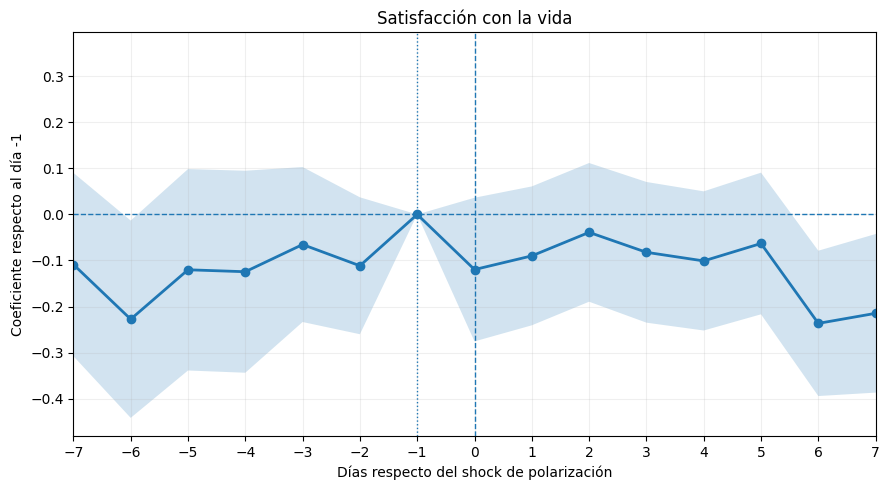

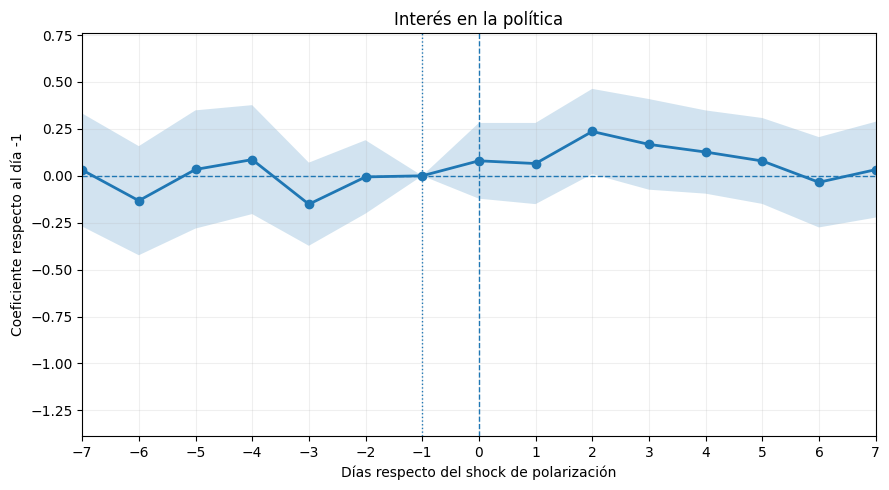

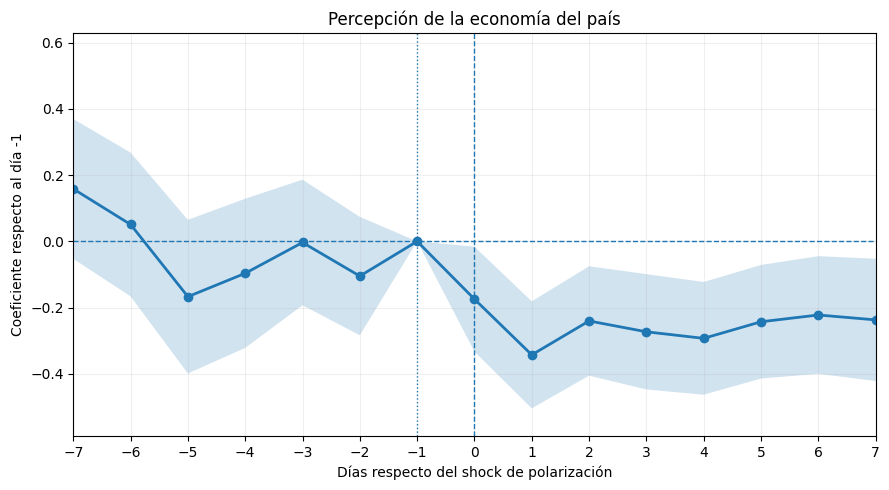

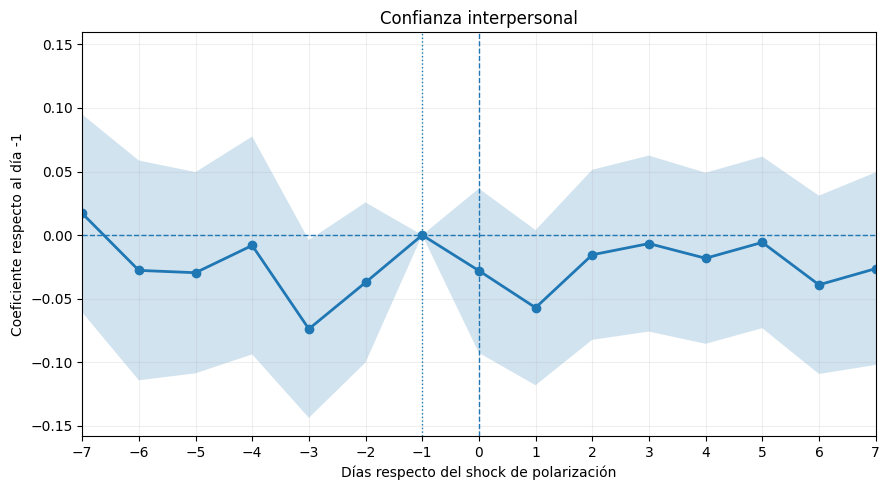

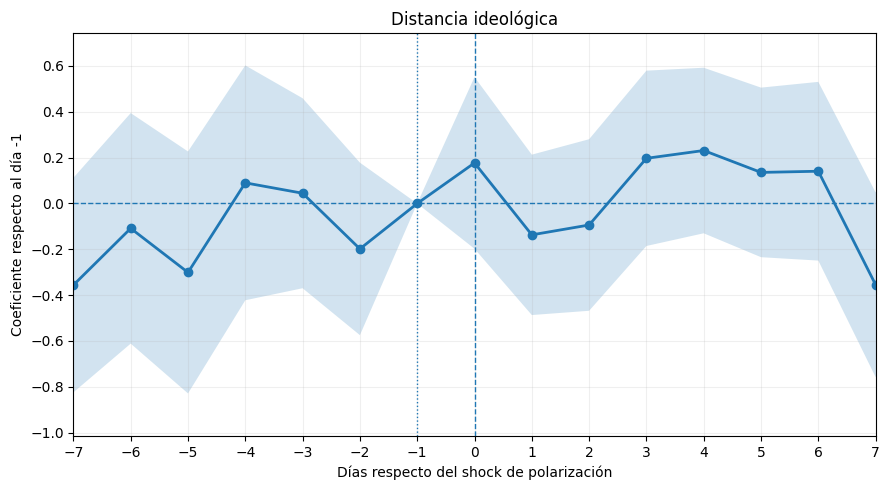

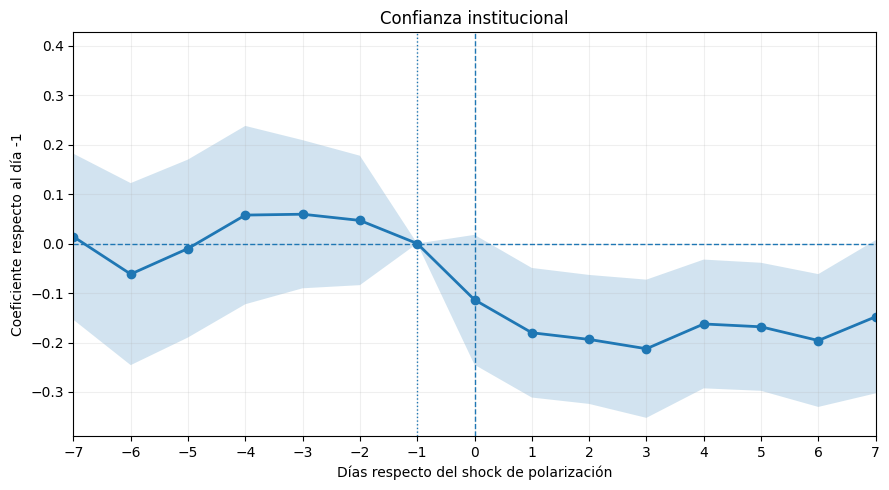

In [14]:
import matplotlib.pyplot as plt

# ============================================================
# GRÁFICOS DE TODAS LAS VARIABLES
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'left_right_distance',
    'confianza_institucional'
]

titulos = {
    'life_satisfaction': 'Satisfacción con la vida',
    'interest_politics': 'Interés en la política',
    'econ_country': 'Percepción de la economía del país',
    'trust_people': 'Confianza interpersonal',
    'left_right_distance': 'Distancia ideológica',
    'confianza_institucional': 'Confianza institucional'
}

for variable in variables:

    r = resultados_event_study[
        resultados_event_study['variable'] == variable
    ].copy()

    if len(r) == 0:
        continue

    plt.figure(figsize=(9, 5))

    # Intervalo de confianza
    plt.fill_between(
        r['dia'],
        r['ci_low'],
        r['ci_high'],
        alpha=0.20
    )

    # Coeficientes
    plt.plot(
        r['dia'],
        r['beta'],
        marker='o',
        linewidth=2
    )

    # Línea horizontal en cero
    plt.axhline(
        0,
        linestyle='--',
        linewidth=1
    )

    # Línea vertical en el día del shock
    plt.axvline(
        0,
        linestyle='--',
        linewidth=1
    )

    # Línea del período de referencia
    plt.axvline(
        -1,
        linestyle=':',
        linewidth=1
    )

    plt.title(
        titulos.get(variable, variable)
    )

    plt.xlabel(
        'Días respecto del shock de polarización'
    )

    plt.ylabel(
        'Coeficiente respecto al día -1'
    )

    plt.xticks(
        range(-7, 8)
    )

    plt.xlim(
        -7,
        7
    )

    plt.grid(
        alpha=0.2
    )

    plt.tight_layout()

    plt.show()

# Placebo

In [ ]:
import pandas as pd
import numpy as np

# ============================================================
# CONFIGURACIÓN
# ============================================================

semilla = 123      # Usar None para no fijar la semilla
n_eventos = 13     # Cantidad de fechas aleatorias a generar

rng = np.random.default_rng(semilla)

# ============================================================
# PREPARAR FECHAS DE LAS ENCUESTAS
# ============================================================

fechas = fechas_encuestas.copy()

fechas['fecha_inicio'] = pd.to_datetime(
    fechas['fecha_inicio'], errors='coerce'
)

fechas['fecha_fin'] = pd.to_datetime(
    fechas['fecha_fin'], errors='coerce'
)

# Eliminar países/olas sin fechas válidas
fechas = fechas.dropna(
    subset=['country', 'wave', 'fecha_inicio', 'fecha_fin']
).copy()

# Asegurar que las fechas sean válidas
fechas = fechas[
    fechas['fecha_inicio'] <= fechas['fecha_fin']
].reset_index(drop=True)

# ============================================================
# CÓDIGOS DE PAÍSES
# ============================================================

country_ids = {
    'Argentina': 32,
    'Bolivia': 68,
    'Brazil': 76,
    'Chile': 152,
    'Colombia': 170,
    'Costa Rica': 188,
    'Dominican Republic': 214,
    'Ecuador': 218,
    'El Salvador': 222,
    'Guatemala': 320,
    'Honduras': 340,
    'Mexico': 484,
    'Nicaragua': 558,
    'Panama': 591,
    'Paraguay': 600,
    'Peru': 604,
    'Uruguay': 858,
    'Venezuela': 862
}

# ============================================================
# GENERAR EVENTOS ALEATORIOS
# ============================================================

eventos = []

for _ in range(n_eventos):

    # Elegir aleatoriamente una combinación país-ola
    fila = fechas.iloc[rng.integers(0, len(fechas))]

    inicio = fila['fecha_inicio']
    fin = fila['fecha_fin']

    # Elegir una fecha aleatoria dentro del período de entrevistas
    dias_disponibles = (fin - inicio).days
    desplazamiento = rng.integers(0, dias_disponibles + 1)

    fecha_evento = inicio + pd.Timedelta(
        days=int(desplazamiento)
    )

    eventos.append({
        'country': fila['country'],
        'country_id': int(fila['country']),
        'event_date': fecha_evento.strftime('%d/%m/%Y'),
        'wave': fila['wave']
    })

eventos_aleatorios = pd.DataFrame(eventos)

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# ============================================================
# VARIABLES
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'left_right_distance',
    'confianza_institucional'
]

# ============================================================
# PARÁMETROS
# ============================================================

DIA_MIN = -8
DIA_MAX = 8
DIA_REFERENCIA = -1

# ============================================================
# MASTER: CONSTRUIR FECHA DE ENTREVISTA
# ============================================================

master_es = master.copy()

# Convertir componentes de fecha a numéricos
for col in ['wave', 'mes_real', 'dia_real', 'country']:
    master_es[col] = pd.to_numeric(
        master_es[col],
        errors='coerce'
    )

# Construir fecha de entrevista
master_es['fecha_entrevista'] = pd.to_datetime(
    {
        'year': master_es['wave'],
        'month': master_es['mes_real'],
        'day': master_es['dia_real']
    },
    errors='coerce'
)

# ============================================================
# EVENTOS: NORMALIZAR TIPOS
# ============================================================

eventos_en_ola = eventos_aleatorios.copy()

eventos_en_ola['country_id'] = pd.to_numeric(
    eventos_en_ola['country_id'],
    errors='coerce'
)

eventos_en_ola['wave'] = pd.to_numeric(
    eventos_en_ola['wave'],
    errors='coerce'
)

# Usar event_date como fecha del evento
eventos_en_ola['event_date'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    errors='coerce'
)

# Eliminar eventos sin identificadores o fechas válidas
eventos_en_ola = eventos_en_ola.dropna(
    subset=['country_id', 'wave', 'event_date']
).copy()

eventos_en_ola['country_id'] = (
    eventos_en_ola['country_id'].astype(int)
)

eventos_en_ola['wave'] = (
    eventos_en_ola['wave'].astype(int)
)

# ============================================================
# CONSTRUIR BASE POOLED DE EVENTOS
# ============================================================

observaciones_eventos = []

for i, evento in eventos_en_ola.iterrows():

    country = int(evento['country_id'])
    wave = int(evento['wave'])
    fecha_evento = pd.Timestamp(evento['event_date'])

    # Muestra país × ola
    es = master_es[
        (master_es['country'] == country) &
        (master_es['wave'] == wave)
    ].copy()

    if es.empty:
        print(
            f"Sin observaciones: {evento['country']} "
            f"{fecha_evento.date()}"
        )
        continue

    # Eliminar entrevistas sin fecha válida
    es = es.dropna(
        subset=['fecha_entrevista']
    ).copy()

    # Diferencia en días enteros
    es['dias_evento'] = (
        es['fecha_entrevista'] - fecha_evento
    ).dt.days

    es = es.dropna(
        subset=['dias_evento']
    ).copy()

    es['dias_evento'] = es['dias_evento'].astype('int64')

    # Aplicar ventana
    es = es[
        es['dias_evento'].between(DIA_MIN, DIA_MAX)
    ].copy()

    if es.empty:
        print(
            f"Sin entrevistas en la ventana: "
            f"{evento['country']} {fecha_evento.date()}"
        )
        continue

    # Identificación del evento
    es['event_day'] = fecha_evento
    es['event_id'] = i

    observaciones_eventos.append(es)

# ============================================================
# UNIFICAR EVENTOS
# ============================================================

if not observaciones_eventos:
    raise ValueError(
        "No hay observaciones dentro de las ventanas de los eventos. "
        "Revisá países, olas y fechas."
    )

eventos_pooled = pd.concat(
    observaciones_eventos,
    ignore_index=True
)

eventos_pooled['dias_evento'] = (
    eventos_pooled['dias_evento'].astype('int64')
)

print("Observaciones pooled:", len(eventos_pooled))
print("Días observados:", sorted(
    eventos_pooled['dias_evento'].unique()
))

# ============================================================
# EVENT STUDIES POOLED
# ============================================================

todos_resultados = []
todos_modelos = {}

for variable in variables:

    if variable not in eventos_pooled.columns:
        print(f"No existe la variable: {variable}")
        continue

    data = eventos_pooled.dropna(
        subset=[variable, 'dias_evento']
    ).copy()

    if data.empty:
        print(f"Sin observaciones válidas para {variable}")
        continue

    # Asegurar tipos numéricos
    data[variable] = pd.to_numeric(
        data[variable],
        errors='coerce'
    )

    data['dias_evento'] = pd.to_numeric(
        data['dias_evento'],
        errors='coerce'
    )

    data = data.dropna(
        subset=[variable, 'dias_evento']
    ).copy()

    if data.empty:
        continue

    data['dias_evento'] = (
        data['dias_evento'].round().astype('int64')
    )

    # Verificar la categoría de referencia
    dias_observados = set(data['dias_evento'].unique())

    if DIA_REFERENCIA not in dias_observados:
        print(
            f"No existe día {DIA_REFERENCIA} "
            f"para {variable}. "
            f"Días disponibles: {sorted(dias_observados)}"
        )
        continue

    # --------------------------------------------------------
    # DUMMIES DE DÍAS
    # --------------------------------------------------------

    X = pd.get_dummies(
        data['dias_evento'],
        prefix='dia',
        dtype=float
    )

    # Normalizar nombres para asegurar formato dia_-1, dia_0...
    X.columns = [
        f'dia_{int(col.replace("dia_", ""))}'
        for col in X.columns
    ]

    nombre_ref = f'dia_{DIA_REFERENCIA}'

    if nombre_ref not in X.columns:
        print(
            f"Error en dummies para {variable}. "
            f"Columnas: {X.columns.tolist()}"
        )
        continue

    # Día -1 como referencia
    X = X.drop(columns=[nombre_ref])

    X = sm.add_constant(X, has_constant='add')

    # Asegurar que X e Y sean numéricos
    X = X.astype(float)
    y = data[variable].astype(float)

    # --------------------------------------------------------
    # OLS
    # --------------------------------------------------------

    modelo = sm.OLS(
        y,
        X
    ).fit(
        cov_type='HC1'
    )

    # --------------------------------------------------------
    # RESULTADOS
    # --------------------------------------------------------

    resultados = []

    for dia in range(DIA_MIN, DIA_MAX + 1):

        if dia == DIA_REFERENCIA:
            beta = 0.0
            se = 0.0

        else:
            nombre = f'dia_{dia}'

            if nombre in modelo.params.index:
                beta = modelo.params[nombre]
                se = modelo.bse[nombre]
            else:
                beta = np.nan
                se = np.nan

        resultados.append({
            'dia': dia,
            'beta': beta,
            'se': se
        })

    r = pd.DataFrame(resultados)

    r['ci_low'] = r['beta'] - 1.96 * r['se']
    r['ci_high'] = r['beta'] + 1.96 * r['se']
    r['variable'] = variable
    r['n'] = len(data)

    todos_resultados.append(r)
    todos_modelos[variable] = modelo

# ============================================================
# RESULTADO FINAL
# ============================================================

if not todos_resultados:
    raise ValueError(
        "No se estimó ningún modelo. Revisá los mensajes "
        "de diagnóstico anteriores."
    )

resultados_event_study = (
    pd.concat(todos_resultados, ignore_index=True)
    [
        [
            'variable',
            'dia',
            'beta',
            'se',
            'ci_low',
            'ci_high',
            'n'
        ]
    ]
    .sort_values(['variable', 'dia'])
    .reset_index(drop=True)
)


Sin entrevistas en la ventana: 32 2003-12-08
Sin entrevistas en la ventana: 170 2008-06-09
Sin entrevistas en la ventana: 222 2003-01-08
Observaciones pooled: 1096
Días observados: [np.int64(-8), np.int64(-6), np.int64(-5), np.int64(-4), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Sin observaciones válidas para interest_politics


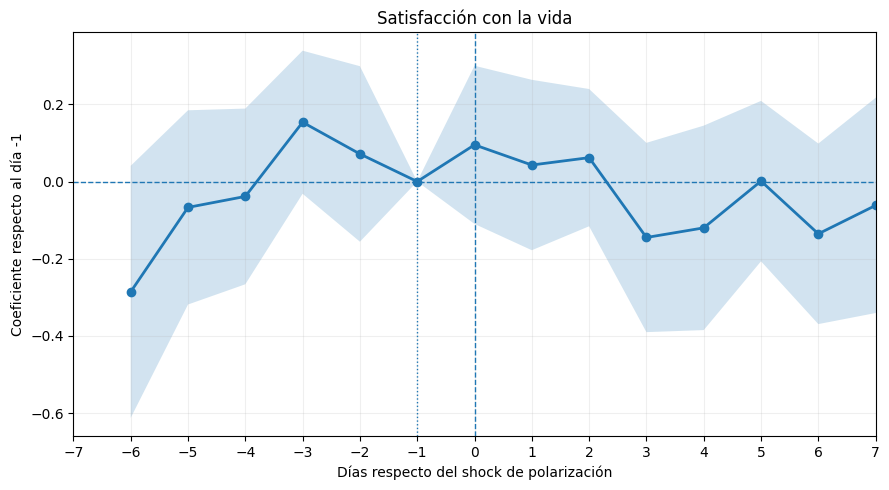

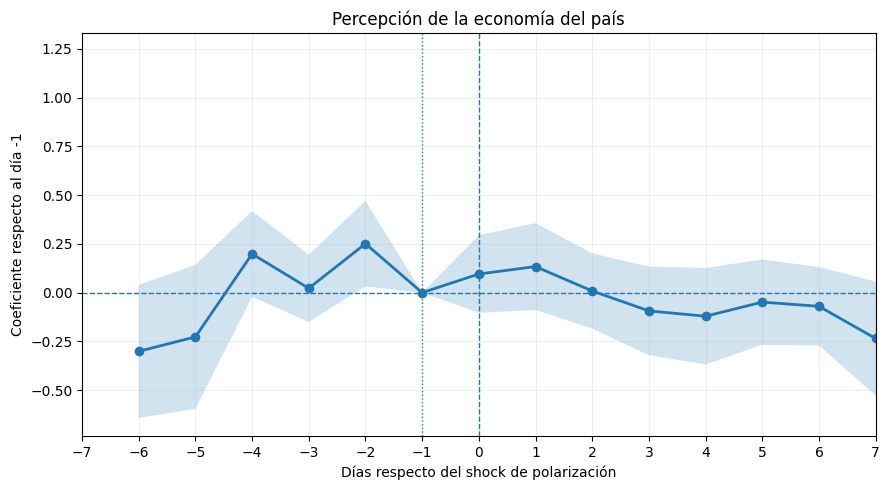

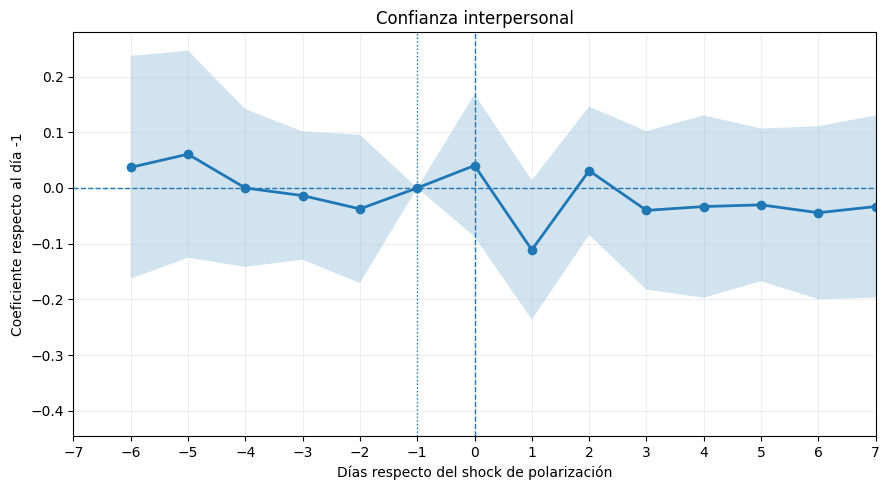

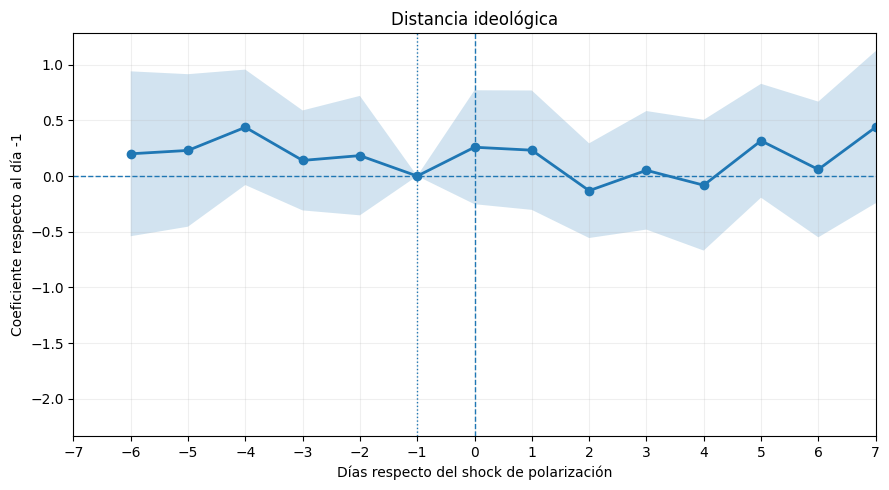

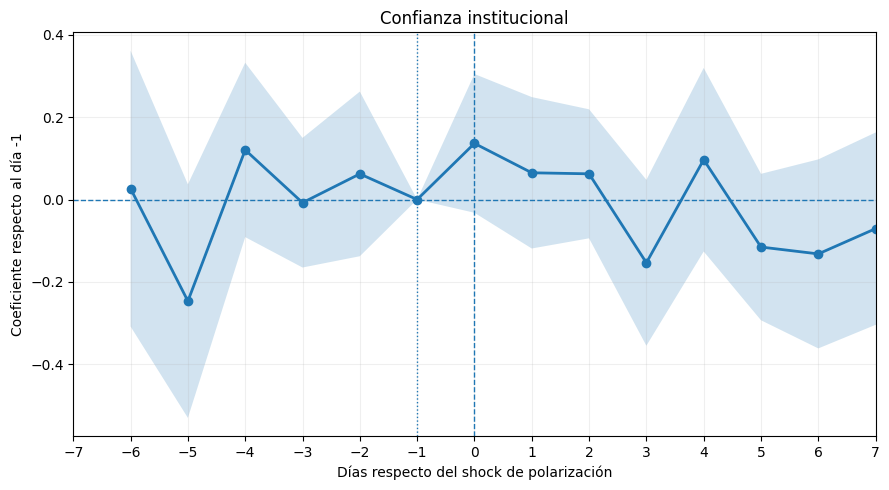

In [ ]:
import matplotlib.pyplot as plt

# ============================================================
# GRÁFICOS DE TODAS LAS VARIABLES
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'left_right_distance',
    'confianza_institucional'
]

titulos = {
    'life_satisfaction': 'Satisfacción con la vida',
    'interest_politics': 'Interés en la política',
    'econ_country': 'Percepción de la economía del país',
    'trust_people': 'Confianza interpersonal',
    'left_right_distance': 'Distancia ideológica',
    'confianza_institucional': 'Confianza institucional'
}

for variable in variables:

    r = resultados_event_study[
        resultados_event_study['variable'] == variable
    ].copy()

    if len(r) == 0:
        continue

    plt.figure(figsize=(9, 5))

    # Intervalo de confianza
    plt.fill_between(
        r['dia'],
        r['ci_low'],
        r['ci_high'],
        alpha=0.20
    )

    # Coeficientes
    plt.plot(
        r['dia'],
        r['beta'],
        marker='o',
        linewidth=2
    )

    # Línea horizontal en cero
    plt.axhline(
        0,
        linestyle='--',
        linewidth=1
    )

    # Línea vertical en el día del shock
    plt.axvline(
        0,
        linestyle='--',
        linewidth=1
    )

    # Línea del período de referencia
    plt.axvline(
        -1,
        linestyle=':',
        linewidth=1
    )

    plt.title(
        titulos.get(variable, variable)
    )

    plt.xlabel(
        'Días respecto del shock de polarización'
    )

    plt.ylabel(
        'Coeficiente respecto al día -1'
    )

    plt.xticks(
        range(-7, 8)
    )

    plt.xlim(
        -7,
        7
    )

    plt.grid(
        alpha=0.2
    )

    plt.tight_layout()

    plt.show()

# Tabla

In [15]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

from itertools import combinations

# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'confianza_institucional',
    'confianza_congreso',
    'confianza_gobierno',
    'confianza_judicial'
]

DIA_MIN = -8
DIA_MAX = 8
DIA_REFERENCIA = -1

# Días incluidos en el promedio posterior
DIAS_POST = list(range(0, DIA_MAX + 1))

# Días incluidos en el test conjunto preevento
DIAS_PRE = [
    d for d in range(DIA_MIN, 0)
    if d != DIA_REFERENCIA
]

# ============================================================
# PREPARAR MASTER
# ============================================================

master_es = master.copy()

for col in ['wave', 'mes_real', 'dia_real', 'country']:
    master_es[col] = pd.to_numeric(
        master_es[col],
        errors='coerce'
    )

master_es['fecha_entrevista'] = pd.to_datetime(
    {
        'year': master_es['wave'],
        'month': master_es['mes_real'],
        'day': master_es['dia_real']
    },
    errors='coerce'
)

# ============================================================
# PREPARAR EVENTOS
# ============================================================

eventos_base = eventos_en_ola.copy()

eventos_base['country_id'] = pd.to_numeric(
    eventos_base['country_id'],
    errors='coerce'
)

eventos_base['wave'] = pd.to_numeric(
    eventos_base['wave'],
    errors='coerce'
)

# dayfirst=True porque las fechas originales están en formato
# DD/MM/YYYY. Si ya son datetime, también funciona.
eventos_base['event_date'] = pd.to_datetime(
    eventos_base['event_date'],
    errors='coerce',
    dayfirst=True
)

eventos_base = eventos_base.dropna(
    subset=['country_id', 'wave', 'event_date']
).copy()

eventos_base['country_id'] = (
    eventos_base['country_id'].astype(int)
)

eventos_base['wave'] = (
    eventos_base['wave'].astype(int)
)

# Identificador único para cada evento
eventos_base = eventos_base.reset_index(drop=True)

eventos_base['event_id'] = np.arange(
    len(eventos_base)
)

print("Eventos disponibles:", len(eventos_base))

Eventos disponibles: 11


In [16]:
# ============================================================
# CATÁLOGO DE ESTUDIOS
# ============================================================


eventos_en_ola = pd.DataFrame([
    {'country': 'Colombia', 'country_id': 170, 'event_date': '17/06/2018'},
    {'country': 'Bolivia', 'country_id': 68, 'event_date': '11/09/2008'},
    {'country': 'Costa Rica', 'country_id': 188, 'event_date': '05/10/2020'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '24/07/2003'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '21/11/2020'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '03/06/2004'},
    {'country': 'Brazil', 'country_id': 76, 'event_date': '17/06/2013'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '05/06/2016'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '10/11/2020'},
    {'country': 'Mexico', 'country_id': 484, 'event_date': '26/02/2023'},
    {'country': 'Chile', 'country_id': 152, 'event_date': '08/03/2023'},
    {'country': 'Uruguay', 'country_id': 858, 'event_date': '08/03/2023'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '30/07/2017'},
    {'country': 'Brazil', 'country_id': 76, 'event_date': '29/10/2006'},
    {'country': 'Ecuador', 'country_id': 218, 'event_date': '15/10/2006'},
    {'country': 'Ecuador', 'country_id': 218, 'event_date': '28/09/2008'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '26/09/2010'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '06/12/2020'}
])

eventos_en_ola['event_id'] = np.arange(
    len(eventos_en_ola)
)

estudios = [
    {
        'nombre': 'LLM',
        'eventos': list(range(6))
    },
    {
        'nombre': 'LLM 2',
        'eventos': [5,6,7,8,9]
    },
    {
        'nombre': 'LLMs',
        'eventos': list(range(10))
    },
    {
        'nombre': 'Base protestas',
        'eventos': [10,11]
    },
    {
        'nombre': 'Elecciones',
        'eventos': [0, 7,13,14,15,16,17]
    },
    {
        'nombre': 'Todos',
        'eventos': list(range(18))
    },
    {
        'nombre': 'Todos sin elecciones',
        'eventos': list(range(13))
    }

]

for _, evento in eventos_en_ola.iterrows():

    fecha = pd.Timestamp(evento['event_date']).strftime('%d/%m/%Y')

    estudios.append({
        'nombre': f"{evento['country']} - {fecha}",
        'eventos': [int(evento['event_id'])]
    })

In [17]:
# ============================================================
# CONSTRUIR BASE DE UN ESTUDIO
# ============================================================

eventos_base=eventos_en_ola.copy()

def construir_base_estudio(event_ids):

    eventos_seleccionados = eventos_base[
        eventos_base['event_id'].isin(event_ids)
    ].copy()

    observaciones = []

    for _, evento in eventos_seleccionados.iterrows():

        country = int(evento['country_id'])
        wave = int(evento['wave'])
        fecha_evento = pd.Timestamp(evento['event_date'])

        es = master_es[
            (master_es['country'] == country) &
            (master_es['wave'] == wave)
        ].copy()

        es = es.dropna(
            subset=['fecha_entrevista']
        ).copy()

        if es.empty:
            continue

        es['dias_evento'] = (
            es['fecha_entrevista'] - fecha_evento
        ).dt.days

        es = es[
            es['dias_evento'].between(DIA_MIN, DIA_MAX)
        ].copy()

        if es.empty:
            continue

        es['dias_evento'] = es['dias_evento'].astype(int)

        es['event_id'] = int(evento['event_id'])

        observaciones.append(es)

    if not observaciones:
        return pd.DataFrame()

    return pd.concat(
        observaciones,
        ignore_index=True
    )


eventos_base['event_date'] = pd.to_datetime(
    eventos_base['event_date'],
    format='%d/%m/%Y',
    errors='coerce'
)

# ============================================================
# ESTIMAR UN EVENT STUDY Y RESUMIRLO
# CON EFECTOS FIJOS POR LOCALIDAD (PAÍS × CIUDAD)
# ============================================================

def estimar_estudio(nombre_estudio, event_ids):

    data_base = construir_base_estudio(event_ids)

    if data_base.empty:
        print(f"Sin observaciones: {nombre_estudio}")
        return [], []

    resumen = []
    dinamica = []

    # --------------------------------------------------------
    # IDENTIFICAR COLUMNAS
    # --------------------------------------------------------

    COL_PAIS = next(
        (c for c in ["country", "pais", "país", "COUNTRY"]
         if c in data_base.columns),
        None
    )

    if COL_PAIS is None:
        raise ValueError(
            "No se encontró una columna de país."
        )

    if "city" not in data_base.columns:
        raise ValueError(
            "No existe la columna city."
        )

    # --------------------------------------------------------
    # ESTIMACIONES POR VARIABLE
    # --------------------------------------------------------

    for variable in variables:

        if variable not in data_base.columns:
            continue

        data = data_base.copy()

        data[variable] = pd.to_numeric(
            data[variable],
            errors='coerce'
        )

        data['dias_evento'] = pd.to_numeric(
            data['dias_evento'],
            errors='coerce'
        )

        data = data.dropna(
            subset=[variable, 'dias_evento', COL_PAIS, 'city']
        ).copy()

        if data.empty:
            continue

        data['dias_evento'] = (
            data['dias_evento'].round().astype('int64')
        )

        # ----------------------------------------------------
        # VERIFICAR DÍA DE REFERENCIA
        # ----------------------------------------------------

        dias_observados = set(
            data['dias_evento'].unique()
        )

        if DIA_REFERENCIA not in dias_observados:
            print(
                f"No existe día {DIA_REFERENCIA} "
                f"para {variable}."
            )
            continue

        # ----------------------------------------------------
        # IDENTIFICADOR DE LOCALIDAD: PAÍS × CIUDAD
        # ----------------------------------------------------

        data['_localidad'] = (
            data[COL_PAIS].astype('string')
            + '_'
            + data['city'].astype('string')
        )

        # ----------------------------------------------------
        # DUMMIES DE DÍAS
        # ----------------------------------------------------

        X_dias = pd.get_dummies(
            data['dias_evento'],
            prefix='dia',
            dtype=float
        )

        X_dias.columns = [
            f'dia_{int(col.replace("dia_", ""))}'
            for col in X_dias.columns
        ]

        nombre_ref = f'dia_{DIA_REFERENCIA}'

        if nombre_ref not in X_dias.columns:
            continue

        X_dias = X_dias.drop(
            columns=[nombre_ref]
        )

        # ----------------------------------------------------
        # DUMMIES DE LOCALIDAD
        # ----------------------------------------------------

        X_city = pd.get_dummies(
            data['_localidad'],
            prefix='city',
            drop_first=True,
            dtype=float
        )

        # ----------------------------------------------------
        # MATRIZ DE REGRESORES
        # ----------------------------------------------------

        X = pd.concat(
            [
                X_dias.reset_index(drop=True),
                X_city.reset_index(drop=True)
            ],
            axis=1
        )

        X = sm.add_constant(
            X,
            has_constant='add'
        ).astype(float)

        y = data[variable].astype(float).reset_index(drop=True)

        # ----------------------------------------------------
        # OLS CON ERRORES ESTÁNDAR ROBUSTOS
        # ----------------------------------------------------

        modelo = sm.OLS(y, X).fit(
            cov_type='HC1'
        )

        # ----------------------------------------------------
        # COEFICIENTES DINÁMICOS
        # ----------------------------------------------------

        for dia in range(DIA_MIN, DIA_MAX + 1):

            nombre = f'dia_{dia}'

            if dia == DIA_REFERENCIA:
                beta = 0.0
                se = 0.0
                pvalor = np.nan

            elif nombre in modelo.params.index:
                beta = modelo.params[nombre]
                se = modelo.bse[nombre]
                pvalor = modelo.pvalues[nombre]

            else:
                beta = np.nan
                se = np.nan
                pvalor = np.nan

            dinamica.append({
                'estudio': nombre_estudio,
                'variable': variable,
                'dia': dia,
                'beta': beta,
                'se': se,
                'pvalor': pvalor,
                'n': int(modelo.nobs)
            })

        # ----------------------------------------------------
        # TEST CONJUNTO DE COEFICIENTES PRE-EVENTO
        # ----------------------------------------------------

        nombres_pre = [
            f'dia_{d}' for d in DIAS_PRE
            if f'dia_{d}' in modelo.params.index
        ]

        if nombres_pre:

            restricciones = np.zeros(
                (len(nombres_pre), len(modelo.params))
            )

            for i, nombre in enumerate(nombres_pre):
                restricciones[
                    i,
                    modelo.params.index.get_loc(nombre)
                ] = 1

            test_pre = modelo.f_test(restricciones)

            p_pre = float(
                np.asarray(test_pre.pvalue).item()
            )

        else:
            p_pre = np.nan

        # ----------------------------------------------------
        # EFECTO PROMEDIO POST-EVENTO
        # ----------------------------------------------------

        nombres_post = [
            f'dia_{d}' for d in DIAS_POST
            if f'dia_{d}' in modelo.params.index
        ]

        if nombres_post:

            R = np.zeros(len(modelo.params))

            for nombre in nombres_post:
                R[modelo.params.index.get_loc(nombre)] = (
                    1 / len(nombres_post)
                )

            test_post = modelo.t_test(R)

            beta_post = float(
                np.asarray(test_post.effect).item()
            )

            se_post = float(
                np.asarray(test_post.sd).item()
            )

            p_post = float(
                np.asarray(test_post.pvalue).item()
            )

        else:
            beta_post = np.nan
            se_post = np.nan
            p_post = np.nan

        # ----------------------------------------------------
        # RESUMEN
        # ----------------------------------------------------

        resumen.append({
            'estudio': nombre_estudio,
            'variable': variable,
            'p_preevento': p_pre,
            'efecto_post': beta_post,
            'se_post': se_post,
            'p_post': p_post,
            'n': int(modelo.nobs),
            'n_eventos': len(event_ids),
            'n_localidades': data['_localidad'].nunique()
        })

    return resumen, dinamica

In [18]:
# ============================================================
# EJECUTAR TODOS LOS ESTUDIOS
# ============================================================

# Asegurar que existan 'wave' y 'country_id' numéricos en la base de eventos
if 'event_date' in eventos_base.columns:
    eventos_base['event_date_dt'] = pd.to_datetime(eventos_base['event_date'], errors='coerce', dayfirst=True)
    if 'wave' not in eventos_base.columns:
        eventos_base['wave'] = eventos_base['event_date_dt'].dt.year
    if 'country_id' not in eventos_base.columns and 'country_id' in eventos_en_ola.columns:
        eventos_base['country_id'] = eventos_en_ola['country_id']
todos_resumenes = []
todas_dinamicas = []

for estudio in estudios:

    resumen, dinamica = estimar_estudio(
        nombre_estudio=estudio['nombre'],
        event_ids=estudio['eventos']
    )

    todos_resumenes.extend(resumen)
    todas_dinamicas.extend(dinamica)


# ============================================================
# TABLA DE SÍNTESIS: FORMATO PARA LECTURA / PAPER
# ============================================================

tabla_resumen = pd.DataFrame(todos_resumenes)

if not tabla_resumen.empty:

    # Formato numérico
    columnas_decimales = [
        'efecto_post',
        'se_post'
    ]

    for col in columnas_decimales:
        tabla_resumen[col] = pd.to_numeric(
            tabla_resumen[col],
            errors='coerce'
        ).round(3)

    # Formato de p-valores
    def formato_p(p):
        if pd.isna(p):
            return ''
        if p < 0.001:
            return '<0.001'
        return f'{p:.3f}'

    tabla_resumen['p_preevento'] = (
        tabla_resumen['p_preevento'].apply(formato_p)
    )

    tabla_resumen['p_post'] = (
        tabla_resumen['p_post'].apply(formato_p)
    )

    # Estrellas de significatividad
    def estrellas(p):
        if pd.isna(p):
            return ''
        if p < 0.01:
            return '***'
        elif p < 0.05:
            return '**'
        elif p < 0.10:
            return '*'
        return ''

    tabla_resumen['significatividad'] = (
        tabla_resumen['p_post']
        .replace({'': np.nan, '<0.001': 0.0005})
        .pipe(pd.to_numeric, errors='coerce')
        .apply(estrellas)
    )

    # Mostrar el efecto junto con las estrellas
    tabla_resumen['efecto_post'] = (
        tabla_resumen['efecto_post'].map(
            lambda x: f'{x:.3f}' if pd.notna(x) else ''
        )
        + tabla_resumen['significatividad']
    )

    # N como entero
    tabla_resumen['n'] = (
        pd.to_numeric(tabla_resumen['n'], errors='coerce')
        .astype('Int64')
    )

    tabla_resumen['n_eventos'] = (
        pd.to_numeric(
            tabla_resumen['n_eventos'], errors='coerce'
        ).astype('Int64')
    )

    # Renombrar columnas
    tabla_resumen = tabla_resumen.rename(columns={
        'estudio': 'Estudio',
        'variable': 'Variable dependiente',
        'p_preevento': 'p-valor preevento',
        'efecto_post': 'Efecto promedio post',
        'se_post': 'Error estándar',
        'p_post': 'p-valor post',
        'n': 'N',
        'n_eventos': 'N.º eventos'
    })

    tabla_resumen = tabla_resumen[
        [
            'Estudio',
            'Variable dependiente',
            'p-valor preevento',
            'Efecto promedio post',
            'Error estándar',
            'p-valor post',
            'N',
            'N.º eventos'
        ]
    ]

display(tabla_resumen[:20])

No existe día -1 para life_satisfaction.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.
No existe día -1 para life_satisfaction.
No existe día -1 para interest_politics.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.
No existe día -1 para life_satisfaction.
No existe día -1 para interest_politics.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 6
  res = self.wald_test(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.p

No existe día -1 para life_satisfaction.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.


/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/62041806.py:216: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not 

,Estudio,Variable dependiente,p-valor preevento,Efecto promedio post,Error estándar,p-valor post,N,N.º eventos
0,LLM,life_satisfaction,0.533,-0.146,0.112,0.191,2785,6
1,LLM,interest_politics,0.655,0.009,0.317,0.977,1834,6
2,LLM,econ_country,0.005,-0.183,0.131,0.163,2778,6
3,LLM,trust_people,0.004,-0.014,0.067,0.833,2702,6
4,LLM,confianza_institucional,0.160,-0.077,0.108,0.478,2755,6
5,LLM,confianza_congreso,0.454,-0.056,0.132,0.671,2639,6
6,LLM,confianza_gobierno,0.194,-0.053,0.171,0.758,2693,6
7,LLM,confianza_judicial,0.288,-0.122,0.133,0.360,2656,6
8,LLM 2,life_satisfaction,0.287,-0.028,0.080,0.728,4226,5
9,LLM 2,interest_politics,0.264,0.172*,0.098,0.080,4012,5


In [19]:
len(tabla_resumen)

163

In [20]:
# ============================================================
# FILTRAR ESTUDIOS: PRE-EVENTO > 0.05 Y POST-EVENTO < 0.05
# ============================================================

# Recuperar p-valores numéricos desde la tabla sin formatear
tabla_filtrada = pd.DataFrame(todos_resumenes)

tabla_filtrada = tabla_filtrada[
    (tabla_filtrada['p_preevento'] > 0.05) &
    (tabla_filtrada['p_post'] < 0.05)
].copy()

tabla_filtrada = tabla_filtrada.sort_values(
    ['estudio', 'variable']
).reset_index(drop=True)

print(
    "Combinaciones estudio-variable que cumplen ambos criterios:",
    len(tabla_filtrada)
)

display(tabla_filtrada)

Combinaciones estudio-variable que cumplen ambos criterios: 22


,estudio,variable,p_preevento,efecto_post,se_post,p_post,n,n_eventos,n_localidades
0,LLM 2,confianza_congreso,0.177137,-0.236263,0.086088,0.006061,4080,5,272
1,LLM 2,confianza_institucional,0.741281,-0.177758,0.069315,0.010333,4219,5,273
2,LLMs,confianza_congreso,0.190027,-0.211042,0.073239,0.003957,5880,10,370
3,LLMs,confianza_institucional,0.619746,-0.183405,0.058881,0.001840,6096,10,373
4,LLMs,confianza_judicial,0.357330,-0.179267,0.076189,0.018627,5923,10,372
5,Mexico - 26/02/2023,econ_country,0.425389,1.258525,0.324537,0.000105,1192,1,88
6,Mexico - 26/02/2023,life_satisfaction,0.335491,0.931792,0.239499,0.000100,1188,1,88
7,Mexico - 26/02/2023,trust_people,0.424190,-0.354923,0.139756,0.011098,1176,1,88
8,Peru - 11/10/2020,confianza_congreso,0.747345,-0.339087,0.126005,0.007123,825,1,46
9,Peru - 11/10/2020,confianza_institucional,0.773018,-0.246091,0.102900,0.016777,831,1,47


In [21]:
# ============================================================
# PREPARAR Y EXPORTAR CUADRO 3 A LATEX
# ============================================================

tabla_latex = tabla_filtrada.copy()

# Abreviar nombres de columnas
tabla_latex = tabla_latex.rename(columns={
    "estudio": "País",
    "variable": "Variable",
    "p_preevento": r"$p_{pre}$",
    "efecto_post": r"$\hat{\beta}_{post}$",
    "se_post": "EE",
    "p_post": r"$p_{post}$",
    "n": r"$N$",
    "n_eventos": "#"
})

# Abreviar nombres de países (ajustar según los valores existentes)
abreviar_paises = {
    "Argentina": "ARG",
    "Bolivia": "BOL",
    "Brazil": "BRA",
    "Chile": "CHL",
    "Colombia": "COL",
    "Costa Rica": "CRI",
    "República Dominicana": "DOM",
    "Ecuador": "ECU",
    "El Salvador": "SLV",
    "Guatemala": "GTM",
    "Honduras": "HND",
    "Mexico": "MEX",
    "Nicaragua": "NIC",
    "Panamá": "PAN",
    "Paraguay": "PRY",
    "Peru": "PER",
    "Uruguay": "URY",
    "Venezuela": "VEN"
}

import re

patron = r"^(" + "|".join(
    re.escape(pais) for pais in abreviar_paises
) + r")(?=\s*-|$)"

tabla_latex["País"] = tabla_latex["País"].str.replace(
    patron,
    lambda m: abreviar_paises[m.group(1)],
    regex=True
)

# Opcional: abreviar nombres largos de variables
abreviar_variables = {
    "life_satisfaction": "Satisfacción",
    "interest_politics": "Interés político",
    "econ_country": "Economía",
    "trust_people": "Conf. interpersonal",
    "left_right_distance": "Dist. ideológica",
    "confianza_institucional": "Conf. institucional",
    "confianza_congreso": "Conf. Congreso",
    "confianza_gobierno": "Conf. Gobierno",
    "confianza_judicial": "Conf. judicial"
}

tabla_latex["Variable"] = (
    tabla_latex["Variable"].replace(abreviar_variables)
)


# Exportar
latex = tabla_latex.to_latex(
    index=False,
    escape=False,
    na_rep="",
    float_format="%.3f",
    column_format="llrrrrrr",
    caption="Estudios seleccionados según los criterios pre y post-evento",
    label="tab:estudios_filtrados"
)

with open("Cuadro 3.tex", "w", encoding="utf-8") as f:
    f.write(latex)

print(latex)

\begin{table}
\caption{Estudios seleccionados según los criterios pre y post-evento}
\label{tab:estudios_filtrados}
\begin{tabular}{llrrrrrr}
\toprule
País & Variable & $p_{pre}$ & $\hat{\beta}_{post}$ & EE & $p_{post}$ & $N$ & # & n_localidades \\
\midrule
LLM 2 & Conf. Congreso & 0.177 & -0.236 & 0.086 & 0.006 & 4080 & 5 & 272 \\
LLM 2 & Conf. institucional & 0.741 & -0.178 & 0.069 & 0.010 & 4219 & 5 & 273 \\
LLMs & Conf. Congreso & 0.190 & -0.211 & 0.073 & 0.004 & 5880 & 10 & 370 \\
LLMs & Conf. institucional & 0.620 & -0.183 & 0.059 & 0.002 & 6096 & 10 & 373 \\
LLMs & Conf. judicial & 0.357 & -0.179 & 0.076 & 0.019 & 5923 & 10 & 372 \\
MEX - 26/02/2023 & Economía & 0.425 & 1.259 & 0.325 & 0.000 & 1192 & 1 & 88 \\
MEX - 26/02/2023 & Satisfacción & 0.335 & 0.932 & 0.239 & 0.000 & 1188 & 1 & 88 \\
MEX - 26/02/2023 & Conf. interpersonal & 0.424 & -0.355 & 0.140 & 0.011 & 1176 & 1 & 88 \\
PER - 11/10/2020 & Conf. Congreso & 0.747 & -0.339 & 0.126 & 0.007 & 825 & 1 & 46 \\
PER - 11/10/20

# Composición de la muestra

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

VARIABLES = [
    "sexo",
    "education",
    "age",
    "civil_status",
    "city"
]

DIA_MIN = -8
DIA_MAX = 8

resultados = []

for estudio in estudios:
    nombre = estudio["nombre"]
    event_ids = estudio["eventos"]

    # Reconstruir la base del estudio
    df = construir_base_estudio(event_ids).copy()

    # Mantener la ventana de análisis
    df = df[
        df["dias_evento"].between(DIA_MIN, DIA_MAX)
    ].copy()

    # Definición de períodos
    pre = df[df["dias_evento"] < 0]
    post = df[df["dias_evento"] >= 0]

    for variable in VARIABLES:
        if variable not in df.columns:
            continue

        x_pre = pd.to_numeric(pre[variable], errors="coerce").dropna()
        x_post = pd.to_numeric(post[variable], errors="coerce").dropna()

        if len(x_pre) < 2 or len(x_post) < 2:
            continue

        # Diferencia de medias: post - pre
        prueba = ttest_ind(
            x_post,
            x_pre,
            equal_var=False,
            nan_policy="omit"
        )

        resultados.append({
            "Estudio": nombre,
            "Variable": variable,
            "Media pre": x_pre.mean(),
            "Media post": x_post.mean(),
            "Diferencia (post - pre)": x_post.mean() - x_pre.mean(),
            "Error estándar diferencia": np.sqrt(
                x_post.var(ddof=1) / len(x_post)
                + x_pre.var(ddof=1) / len(x_pre)
            ),
            "p-valor diferencia": prueba.pvalue,
            "N pre": len(x_pre),
            "N post": len(x_post),
        })

tabla_medias = pd.DataFrame(resultados)

tabla_medias_filtrada = tabla_medias[
    tabla_medias["p-valor diferencia"] < 0.001
]

display(
    tabla_medias_filtrada.round(4).sort_values(
        ["Estudio", "Variable"]
    ).reset_index(drop=True)
)

,Estudio,Variable,Media pre,Media post,Diferencia (post - pre),Error estándar diferencia,p-valor diferencia,N pre,N post
0,Base protestas,city,5.128663e+08,8.463463e+08,3.334800e+08,1.258400e+07,0.0000,853,666
1,Base protestas,education,1.153110e+01,1.073720e+01,-7.938000e-01,1.752000e-01,0.0000,853,666
2,Brazil - 17/06/2013,city,7.600281e+07,7.600307e+07,2.652108e+02,6.412130e+01,0.0000,437,705
3,Ecuador - 15/10/2006,city,2.180113e+08,2.180132e+08,1.943294e+03,3.000149e+02,0.0000,883,317
4,Ecuador - 28/09/2008,city,2.180124e+08,2.180068e+08,-5.601066e+03,5.260266e+02,0.0000,377,221
5,Elecciones,city,3.743536e+08,3.325065e+08,-4.184710e+07,9.500980e+06,0.0000,1942,1355
6,Elecciones,education,8.673000e+00,9.248000e+00,5.750000e-01,1.655000e-01,0.0005,1942,1355
7,LLM,city,7.105382e+08,2.668230e+08,-4.437152e+08,9.324409e+06,0.0000,1034,1789
8,LLM,civil_status,1.615900e+00,1.518900e+00,-9.710000e-02,2.900000e-02,0.0008,828,1775
9,LLM 2,age,3.934450e+01,4.098210e+01,1.637600e+00,4.868000e-01,0.0008,1965,2292


# UESD

In [ ]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests


# ============================================================
# CONFIGURACIÓN
# ============================================================

# Ventana de análisis: debe coincidir con la de tu event study.
DIA_MIN_UESD = -8
DIA_MAX_UESD = 8

# Día 0: fecha del evento. Se incluye en el período post.
# Si preferís excluirlo, cambiá esta opción a True.
EXCLUIR_DIA_CERO = False

# Nivel de confianza
NIVEL_CONF = 0.95


# ============================================================
# ESTIMACIÓN UESD
# ============================================================

def estimar_uesd(nombre_estudio, event_ids):

    data_base = construir_base_estudio(event_ids)

    if data_base.empty:
        print(f"Sin observaciones: {nombre_estudio}")
        return [], []

    if 'dias_evento' not in data_base.columns:
        raise ValueError(
            "La base debe contener la columna 'dias_evento'."
        )

    # Copia y limpieza
    data_base = data_base.copy()

    data_base['dias_evento'] = pd.to_numeric(
        data_base['dias_evento'], errors='coerce'
    )

    data_base = data_base.dropna(
        subset=['dias_evento']
    )

    # Asegurar identificación del evento para los pools
    if 'event_id' not in data_base.columns:
        if len(event_ids) == 1:
            data_base['event_id'] = event_ids[0]
        else:
            raise ValueError(
                "La base agrupada debe conservar event_id "
                "para distinguir los eventos del pool."
            )

    # Restringir a la ventana temporal
    data_base = data_base[
        data_base['dias_evento'].between(
            DIA_MIN_UESD, DIA_MAX_UESD
        )
    ].copy()

    if EXCLUIR_DIA_CERO:
        data_base = data_base[
            data_base['dias_evento'] != 0
        ].copy()

    # Tratamiento: entrevista posterior al evento
    data_base['post'] = (
        data_base['dias_evento'] >= (
            1 if EXCLUIR_DIA_CERO else 0
        )
    ).astype(int)

    resultados = []
    descriptivos = []

    for variable in variables:

        if variable not in data_base.columns:
            continue

        data = data_base.copy()

        data[variable] = pd.to_numeric(
            data[variable], errors='coerce'
        )

        data = data.dropna(
            subset=[variable, 'post', 'event_id']
        ).copy()

        if data.empty or data['post'].nunique() < 2:
            continue

        data[variable] = data[variable].astype(float)

        # ----------------------------------------------------
        # 1. DIFERENCIAS DESCRIPTIVAS PRE/POST
        # ----------------------------------------------------

        pre = data.loc[data['post'] == 0, variable]
        post = data.loc[data['post'] == 1, variable]

        media_pre = pre.mean()
        media_post = post.mean()
        diferencia = media_post - media_pre

        descriptivos.append({
            'estudio': nombre_estudio,
            'variable': variable,
            'media_pre': media_pre,
            'media_post': media_post,
            'diferencia_pre_post': diferencia,
            'n_pre': len(pre),
            'n_post': len(post),
            'n_total': len(data),
            'n_eventos': data['event_id'].nunique()
        })

        # ----------------------------------------------------
        # 2. REGRESIÓN PRE/POST
        # ----------------------------------------------------
        # En pools incluimos efectos fijos de evento.
        # En eventos individuales no son necesarios.
        # HC1 corrige la matriz de varianzas por heterocedasticidad.

        if data['event_id'].nunique() > 1:
            formula = f'Q("{variable}") ~ post + C(event_id)'
        else:
            formula = f'Q("{variable}") ~ post'

        modelo = smf.ols(
            formula=formula,
            data=data
        ).fit(cov_type='HC1')

        beta = modelo.params['post']
        se = modelo.bse['post']
        pvalor = modelo.pvalues['post']

        # Intervalo de confianza del 95%
        ci = modelo.conf_int(alpha=1 - NIVEL_CONF)
        ic_inf = ci.loc['post', 0]
        ic_sup = ci.loc['post', 1]

        resultados.append({
            'estudio': nombre_estudio,
            'variable': variable,
            'efecto_post': beta,
            'se_post': se,
            'ic_inf': ic_inf,
            'ic_sup': ic_sup,
            'p_post': pvalor,
            'n': int(modelo.nobs),
            'n_pre': len(pre),
            'n_post': len(post),
            'n_eventos': data['event_id'].nunique(),
            'r2': modelo.rsquared
        })

    return resultados, descriptivos


# ============================================================
# EJECUTAR PARA TODOS LOS ESTUDIOS
# ============================================================

resultados_uesd = []
descriptivos_uesd = []

for estudio in estudios:

    res, desc = estimar_uesd(
        nombre_estudio=estudio['nombre'],
        event_ids=estudio['eventos']
    )

    resultados_uesd.extend(res)
    descriptivos_uesd.extend(desc)


# ============================================================
# CONSTRUIR TABLAS
# ============================================================

tabla_uesd = pd.DataFrame(resultados_uesd)
tabla_descriptiva_uesd = pd.DataFrame(descriptivos_uesd)

if not tabla_uesd.empty:

    # Corrección exploratoria por pruebas múltiples:
    # Benjamini-Hochberg dentro de cada variable,
    # considerando los estudios incluidos.
    tabla_uesd['p_ajustado_BH'] = np.nan

    for variable, indices in tabla_uesd.groupby(
        'variable'
    ).groups.items():

        pvalores = tabla_uesd.loc[
            indices, 'p_post'
        ].values

        validos = np.isfinite(pvalores)

        if validos.any():
            tabla_uesd.loc[
                np.array(list(indices))[validos],
                'p_ajustado_BH'
            ] = multipletests(
                pvalores[validos],
                method='fdr_bh'
            )[1]

    tabla_uesd = tabla_uesd.sort_values(
        ['estudio', 'variable']
    ).reset_index(drop=True)

    tabla_descriptiva_uesd = (
        tabla_descriptiva_uesd
        .sort_values(['estudio', 'variable'])
        .reset_index(drop=True)
    )


    # Exportar resultados
    with pd.ExcelWriter(
        'resultados_uesd.xlsx',
        engine='openpyxl'
    ) as writer:

        tabla_uesd.to_excel(
            writer,
            sheet_name='Regresiones',
            index=False
        )

        tabla_descriptiva_uesd.to_excel(
            writer,
            sheet_name='Promedios_pre_post',
            index=False
        )

else:
    print("No se generaron resultados.")


In [ ]:
# Resultados significativos tras corrección por pruebas múltiples
relevantes = tabla_uesd[
    tabla_uesd['p_ajustado_BH'] < 0.05
].copy()

columnas = [
    'estudio',
    'variable',
    'efecto_post',
    'se_post',
    'ic_inf',
    'ic_sup',
    'p_post',
    'p_ajustado_BH',
    'n',
    'n_eventos'
]

display(
    relevantes[columnas]
    .sort_values('p_ajustado_BH')
    .round(4)
    .reset_index(drop=True)
)

,estudio,variable,efecto_post,se_post,ic_inf,ic_sup,p_post,p_ajustado_BH,n,n_eventos
0,Colombia - 17/06/2018,confianza_gobierno,-2.1228,0.0396,-2.2004,-2.0452,0.0000,0.0000,506,1
1,Brazil - 29/10/2006,trust_people,0.9360,0.0221,0.8927,0.9793,0.0000,0.0000,126,1
2,Colombia - 17/06/2018,trust_people,-0.7909,0.0181,-0.8264,-0.7555,0.0000,0.0000,508,1
3,Colombia - 17/06/2018,confianza_institucional,-1.1242,0.0335,-1.1899,-1.0584,0.0000,0.0000,507,1
4,Colombia - 17/06/2018,confianza_judicial,-1.0808,0.0397,-1.1586,-1.0030,0.0000,0.0000,496,1
5,Colombia - 17/06/2018,life_satisfaction,0.3824,0.0336,0.3165,0.4482,0.0000,0.0000,511,1
6,Mexico - 26/02/2023,life_satisfaction,0.3315,0.0487,0.2360,0.4270,0.0000,0.0000,1188,1
7,Colombia - 17/06/2018,econ_country,-0.2348,0.0348,-0.3031,-0.1665,0.0000,0.0000,512,1
8,LLM 2,confianza_institucional,-0.1592,0.0256,-0.2093,-0.1091,0.0000,0.0000,4219,5
9,LLMs,confianza_institucional,-0.1506,0.0246,-0.1988,-0.1024,0.0000,0.0000,6096,10


# Benjamini-Hochberg (BH)

In [ ]:
from statsmodels.stats.multitest import multipletests
import pandas as pd

tabla = pd.DataFrame(todos_resumenes)

tabla["p_adj_bh"] = multipletests(
    tabla["p_post"],
    method="fdr_bh"
)[1]

tabla["significativo_fdr_5"] = tabla["p_adj_bh"] < 0.05

print("p originales < 0.05:", (tabla["p_post"] < 0.05).sum())
print("p ajustados < 0.05:", (tabla["p_adj_bh"] < 0.05).sum())

print(
    "¿Algún p ajustado es menor que el original?",
    (tabla["p_adj_bh"] < tabla["p_post"] - 1e-12).any()
)

# Aplicar el criterio original y la corrección BH
tabla["cumple_criterio_original"] = (
    (tabla["p_preevento"] > 0.05) &
    (tabla["p_post"] < 0.05)
)

robustos = tabla[
    tabla["cumple_criterio_original"] &
    tabla["significativo_fdr_5"]
].copy()

print("Resultados originales:", tabla["cumple_criterio_original"].sum())
print("Sobreviven a FDR 5%:", len(robustos))

display(
    robustos[
        ["estudio", "variable", "p_preevento", "p_post", "p_adj_bh"]
    ].sort_values("p_adj_bh")
)

p originales < 0.05: 67
p ajustados < 0.05: 59
¿Algún p ajustado es menor que el original? False
Resultados originales: 18
Sobreviven a FDR 5%: 13


,estudio,variable,p_preevento,p_post,p_adj_bh
21,LLMs,confianza_congreso,0.158776,1.679657e-10,1.303734e-09
13,LLM 2,confianza_congreso,0.053938,5.199345e-07,2.648416e-06
4,LLM,confianza_institucional,0.088715,2.682468e-06,1.324977e-05
10,LLM 2,econ_country,0.114575,9.454835e-06,4.532759e-05
102,Mexico - 26/02/2023,life_satisfaction,0.884615,1.278606e-05,5.954653e-05
85,Brazil - 17/06/2013,confianza_gobierno,0.183253,6.632279e-05,2.771952e-04
2,LLM,econ_country,0.360763,1.805614e-04,7.357878e-04
105,Mexico - 26/02/2023,trust_people,0.151123,6.618133e-04,2.568466e-03
74,Venezuela - 06/03/2004,trust_people,0.302234,3.610677e-03,1.154001e-02
153,Venezuela - 26/09/2010,confianza_gobierno,0.142991,3.824049e-03,1.198692e-02


# Sistematización de las pruebas placebo

In [ ]:
eventos_en_ola["event_date"] = pd.to_datetime(
    eventos_en_ola["event_date"],
    format="%d/%m/%Y",
    errors="raise"
)

eventos_en_ola["event_id"] = np.arange(len(eventos_en_ola))
eventos_en_ola["wave"] = eventos_en_ola["event_date"].dt.year

In [ ]:
from collections import Counter

# ============================================================
# CONFIGURACIÓN
# ============================================================

B = 1000
rng = np.random.default_rng(20261015)

VENTANA_EXCLUSION = max(abs(DIA_MIN), abs(DIA_MAX))

# Base de eventos reales, con fechas ya normalizadas
eventos_reales = eventos_en_ola.copy().reset_index(drop=True)

eventos_reales["event_id"] = np.arange(len(eventos_reales))
eventos_reales["country_id"] = pd.to_numeric(
    eventos_reales["country_id"], errors="raise"
).astype(int)

eventos_reales["wave"] = pd.to_numeric(
    eventos_reales["wave"], errors="raise"
).astype(int)

eventos_reales["event_date"] = pd.to_datetime(
    eventos_reales["event_date"], errors="raise"
).dt.normalize()

# Comprobar que los estudios usan los IDs originales
assert set(
    eid
    for estudio in estudios
    for eid in estudio["eventos"]
).issubset(set(eventos_reales["event_id"]))

# Normalizar la base de entrevistas
entrevistas = master_es.copy()
entrevistas["fecha_entrevista"] = pd.to_datetime(
    entrevistas["fecha_entrevista"], errors="coerce"
).dt.normalize()

entrevistas["country"] = pd.to_numeric(
    entrevistas["country"], errors="coerce"
)
entrevistas["wave"] = pd.to_numeric(
    entrevistas["wave"], errors="coerce"
)

# ============================================================
# FECHAS REALES QUE DEBEN EXCLUIRSE
# ============================================================

fechas_reales_por_pais = {
    int(pais): grupo["event_date"].tolist()
    for pais, grupo in eventos_reales.groupby("country_id")
}

# ============================================================
# CANDIDATAS VÁLIDAS PARA CADA EVENTO
# ============================================================

def generar_candidatas(evento):

    pais = int(evento["country_id"])
    ola = int(evento["wave"])

    muestra = entrevistas[
        (entrevistas["country"] == pais) &
        (entrevistas["wave"] == ola)
    ].dropna(subset=["fecha_entrevista"])

    fechas = pd.DatetimeIndex(
        muestra["fecha_entrevista"].drop_duplicates()
    ).sort_values()

    if len(fechas) == 0:
        return []

    # Exigir que la ventana completa quede dentro del rango
    inicio = fechas.min() + pd.Timedelta(days=VENTANA_EXCLUSION)
    fin = fechas.max() - pd.Timedelta(days=VENTANA_EXCLUSION)

    if inicio > fin:
        return []

    # Días en que efectivamente hubo entrevistas
    dias_observados = set(fechas)

    candidatas = []

    for fecha in pd.date_range(inicio, fin, freq="D"):

        # Excluir fechas próximas a CUALQUIER evento real
        fechas_reales = fechas_reales_por_pais.get(pais, [])

        if any(
            abs((fecha - real).days) <= 2 * VENTANA_EXCLUSION
            for real in fechas_reales
        ):
            continue

        # Comprobar el soporte temporal de la ventana placebo
        dias_relativos = {
            (entrevista - fecha).days
            for entrevista in dias_observados
        }

        if DIA_REFERENCIA not in dias_relativos:
            continue

        if not any(d in dias_relativos for d in DIAS_PRE):
            continue

        if not any(d in dias_relativos for d in DIAS_POST):
            continue

        candidatas.append(fecha)

    return candidatas


candidatas_por_evento = {
    int(evento["event_id"]): generar_candidatas(evento)
    for _, evento in eventos_reales.iterrows()
}

sin_candidatas = [
    eid for eid, fechas in candidatas_por_evento.items()
    if len(fechas) == 0
]

print("Candidatas por evento:")

for _, evento in eventos_reales.iterrows():
    eid = int(evento["event_id"])
    print(
        eid,
        evento["country"],
        evento["event_date"].strftime("%d/%m/%Y"),
        len(candidatas_por_evento[eid])
    )

if sin_candidatas:
    print(
        "Se excluyen de la simulación los eventos sin fechas placebo: "
        f"{sin_candidatas}"
    )

eventos_placebo = eventos_reales[
    eventos_reales["event_id"].isin(
        [
            eid for eid, fechas in candidatas_por_evento.items()
            if len(fechas) > 0
        ]
    )
].copy().reset_index(drop=True)

ids_validos = set(eventos_placebo["event_id"].astype(int))

if eventos_placebo.empty:
    raise ValueError(
        "Ningún evento tiene fechas placebo admisibles."
    )

# Conservar solo estudios que tengan eventos disponibles
estudios_placebo = []

for estudio in estudios:
    ids = [
        int(eid) for eid in estudio["eventos"]
        if int(eid) in ids_validos
    ]

    if ids:
        estudios_placebo.append({
            **estudio,
            "eventos": ids
        })

print(f"Eventos originales: {len(eventos_reales)}")
print(f"Eventos utilizados: {len(eventos_placebo)}")
print(f"Estudios utilizados: {len(estudios_placebo)}")

# ============================================================
# SORTEAR UN CONJUNTO COMPLETO DE FECHAS PLACEBO
# ============================================================

def sortear_fechas_placebo(max_intentos=500):

    ids = list(eventos_placebo["event_id"].astype(int))

    for _ in range(max_intentos):

        # Sortear primero los eventos con menos alternativas
        orden = sorted(
            ids,
            key=lambda eid: len(candidatas_por_evento[eid])
        )

        # Aleatorizar empates
        grupos = {}
        for eid in orden:
            grupos.setdefault(
                len(candidatas_por_evento[eid]), []
            ).append(eid)

        orden = []
        for grupo in grupos.values():
            rng.shuffle(grupo)
            orden.extend(grupo)

        asignadas = {}
        fechas_por_pais_ola = {}

        valido = True

        for eid in orden:

            evento = eventos_placebo[eventos_placebo["event_id"] == eid].iloc[0]
            pais = int(evento["country_id"])
            ola = int(evento["wave"])

            clave = (pais, ola)

            candidatas = list(candidatas_por_evento[eid])
            rng.shuffle(candidatas)

            elegida = None

            for fecha in candidatas:

                # Evitar solapamiento entre ventanas placebo
                anteriores = fechas_por_pais_ola.get(clave, [])

                if any(
                    abs((fecha - otra).days)
                    <= 2 * VENTANA_EXCLUSION
                    for otra in anteriores
                ):
                    continue

                elegida = fecha
                break

            if elegida is None:
                valido = False
                break

            asignadas[eid] = elegida

            fechas_por_pais_ola.setdefault(
                clave, []
            ).append(elegida)

        if valido:
            return asignadas

    return None


# ============================================================
# ESTADÍSTICOS DE UNA RÉPLICA
# ============================================================

def resumir_replica(resumenes):

    df = pd.DataFrame(resumenes)

    if df.empty:
        return None

    df["p_preevento"] = pd.to_numeric(
        df["p_preevento"], errors="coerce"
    )
    df["p_post"] = pd.to_numeric(
        df["p_post"], errors="coerce"
    )

    df["efecto_post"] = pd.to_numeric(
        df["efecto_post"], errors="coerce"
    )

    df = df.dropna(
        subset=["p_preevento", "p_post", "efecto_post"]
    ).copy()

    df["cumple_ambos"] = (
        (df["p_preevento"] > 0.05) &
        (df["p_post"] < 0.01)
    )

    return {
        "n_pruebas": len(df),
        "n_cumplen_ambos": int(df["cumple_ambos"].sum()),
        "n_positivos": int(
            (df["cumple_ambos"] & (df["efecto_post"] > 0)).sum()
        ),
        "n_negativos": int(
            (df["cumple_ambos"] & (df["efecto_post"] < 0)).sum()
        )
    }


# ============================================================
# SIMULACIÓN
# ============================================================

resultados_placebo = []

eventos_base_original = eventos_base.copy()

try:

    for b in range(B):

        fechas_placebo = sortear_fechas_placebo()

        if fechas_placebo is None:
            print(f"Réplica {b}: no se encontró asignación válida.")
            continue

        # Sustituir las fechas, sin modificar países, olas ni IDs
        eventos_base = eventos_placebo.copy()

        eventos_base["event_date"] = eventos_base["event_id"].map(
            fechas_placebo
        )

        resumen_replica = []

        # Repetir exactamente los estudios definidos
        for estudio in estudios_placebo:

            resumen, _ = estimar_estudio(
                nombre_estudio=estudio["nombre"],
                event_ids=estudio["eventos"]
            )

            resumen_replica.extend(resumen)

        estadisticos = resumir_replica(resumen_replica)

        if estadisticos is None:
            continue

        estadisticos["replica"] = b
        resultados_placebo.append(estadisticos)

        if (b + 1) % 25 == 0:
            print(f"Completadas {b + 1}/{B} réplicas")

finally:
    # Restaurar la base original incluso si ocurre un error
    eventos_base = eventos_base_original.copy()


placebos = pd.DataFrame(resultados_placebo)

display(placebos.describe())

Candidatas por evento:
0 Colombia 17/06/2018 11
1 Bolivia 11/09/2008 0
2 Costa Rica 05/10/2020 20
3 Guatemala 24/07/2003 0
4 Guatemala 21/11/2020 6
5 Venezuela 03/06/2004 0
6 Brazil 17/06/2013 0
7 Peru 05/06/2016 0
8 Peru 10/11/2020 0
9 Mexico 26/02/2023 0
10 Chile 08/03/2023 0
11 Uruguay 08/03/2023 0
12 Venezuela 30/07/2017 6
13 Brazil 29/10/2006 0
14 Ecuador 15/10/2006 0
15 Ecuador 28/09/2008 2
16 Venezuela 26/09/2010 0
17 Venezuela 06/12/2020 14
Se excluyen de la simulación los eventos sin fechas placebo: [1, 3, 5, 6, 7, 8, 9, 10, 11, 13, 14, 16]
Eventos originales: 18
Eventos utilizados: 6
Estudios utilizados: 11


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 4, but rank is 2
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 4, but rank is 3
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 6
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but

Completadas 25/1000 réplicas


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 4, but rank is 2
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 4, but rank is 3
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 5
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 5
  res = self.wald_test(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but

Completadas 50/1000 réplicas


In [ ]:
observado = resumir_replica(todos_resumenes)

print("Resultados observados:")
print(observado)

print("\nDistribución placebo:")
display(
    placebos[
        ["n_cumplen_ambos", "n_positivos", "n_negativos"]
    ].quantile([0, .05, .25, .50, .75, .95, 1])
)

In [ ]:
T_obs = observado["n_cumplen_ambos"]
T_placebo = placebos["n_cumplen_ambos"]

p_empirico = (
    1 + (T_placebo >= T_obs).sum()
) / (
    1 + len(T_placebo)
)

print("T observado:", T_obs)
print("Mediana placebo:", T_placebo.median())
print("Percentil 95 placebo:", T_placebo.quantile(.95))
print("p empírico:", p_empirico)

# leave-one-event-out

In [ ]:
# ============================================================
# LEAVE-ONE-EVENT-OUT
# ============================================================

import pandas as pd
import numpy as np

# Guardar la base para restaurarla al terminar
eventos_base_original = eventos_base.copy()

# Etiquetas de los eventos
catalogo_eventos = eventos_en_ola.copy().reset_index(drop=True)
catalogo_eventos["event_id"] = np.arange(len(catalogo_eventos))

def etiqueta_evento(eid):
    fila = catalogo_eventos.loc[
        catalogo_eventos["event_id"] == int(eid)
    ].iloc[0]

    fecha = pd.to_datetime(
        fila["event_date"], dayfirst=True
    ).strftime("%d/%m/%Y")

    return f'{fila["country"]} - {fecha}'


resultados_loo = []

try:
    for estudio in estudios:

        nombre = estudio["nombre"]
        ids = list(dict.fromkeys(
            int(eid) for eid in estudio["eventos"]
        ))

        # El ejercicio solo tiene sentido para estudios agrupados
        if len(ids) < 2:
            continue

        # ----------------------------------------------------
        # Estimación original, con todos los eventos
        # ----------------------------------------------------
        resumen_completo, _ = estimar_estudio(
            nombre_estudio=nombre,
            event_ids=ids
        )

        for r in resumen_completo:
            resultados_loo.append({
                **r,
                "estudio_original": nombre,
                "evento_excluido_id": None,
                "evento_excluido": "Ninguno",
                "n_eventos_original": len(ids)
            })

        # ----------------------------------------------------
        # Reestimar excluyendo un evento por vez
        # ----------------------------------------------------
        for eid in ids:

            ids_reducidos = [x for x in ids if x != eid]

            resumen_loo, _ = estimar_estudio(
                nombre_estudio=nombre,
                event_ids=ids_reducidos
            )

            for r in resumen_loo:
                resultados_loo.append({
                    **r,
                    "estudio_original": nombre,
                    "evento_excluido_id": eid,
                    "evento_excluido": etiqueta_evento(eid),
                    "n_eventos_original": len(ids)
                })

finally:
    eventos_base = eventos_base_original.copy()


loo = pd.DataFrame(resultados_loo)

# Identificar las estimaciones completas y las LOO
loo["tipo"] = np.where(
    loo["evento_excluido_id"].isna(),
    "Completo",
    "Leave-one-out"
)

# Ordenar y mostrar resultados principales
columnas = [
    "estudio_original",
    "variable",
    "tipo",
    "evento_excluido",
    "n_eventos",
    "efecto_post",
    "se_post",
    "p_post",
    "p_preevento"
]

In [ ]:
# ============================================================
# RESUMEN LEAVE-ONE-OUT PARA REVISAR ROBUSTEZ
# ============================================================

resumen_loo = []

for (estudio, variable), grupo in loo.groupby(
    ["estudio_original", "variable"]
):
    completo = grupo[grupo["tipo"] == "Completo"]
    excluidos = grupo[grupo["tipo"] == "Leave-one-out"]

    if completo.empty or excluidos.empty:
        continue

    original = completo.iloc[0]
    efecto_original = original["efecto_post"]
    p_original = original["p_post"]

    if pd.isna(efecto_original) or pd.isna(p_original):
        continue

    efectos = pd.to_numeric(
        excluidos["efecto_post"], errors="coerce"
    ).dropna()

    valores_p = pd.to_numeric(
        excluidos["p_post"], errors="coerce"
    )

    if efectos.empty:
        continue

    resumen_loo.append({
        "estudio": estudio,
        "variable": variable,
        "n_eventos": original["n_eventos"],
        "efecto_original": efecto_original,
        "p_original": p_original,
        "efecto_min_LOO": efectos.min(),
        "efecto_max_LOO": efectos.max(),
        "max_cambio_abs": (efectos - efecto_original).abs().max(),
        "cambia_signo": bool(
            ((efectos * efecto_original) < 0).any()
        ),
        "pierde_significacion_5%": bool(
            (p_original < 0.05) and (valores_p >= 0.05).any()
        ),
        "pierde_significacion_1%": bool(
            (p_original < 0.01) and (valores_p >= 0.01).any()
        ),
        "peor_exclusion": excluidos.loc[
            (pd.to_numeric(excluidos["efecto_post"], errors="coerce")
             - efecto_original).abs().idxmax(),
            "evento_excluido"
        ] if pd.to_numeric(
            excluidos["efecto_post"], errors="coerce"
        ).notna().any() else None
    })

resumen_loo = pd.DataFrame(resumen_loo)

display(
    resumen_loo.sort_values(
        ["cambia_signo", "pierde_significacion_5%", "max_cambio_abs"],
        ascending=[False, False, False]
    ).round(4)
)

# Con controles y FE

In [31]:
# ============================================================
# CATÁLOGO DE ESTUDIOS
# ============================================================


eventos_en_ola = pd.DataFrame([
    {'country': 'Colombia', 'country_id': 170, 'event_date': '17/06/2018'},
    {'country': 'Bolivia', 'country_id': 68, 'event_date': '11/09/2008'},
    {'country': 'Costa Rica', 'country_id': 188, 'event_date': '05/10/2020'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '24/07/2003'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '21/11/2020'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '03/06/2004'},
    {'country': 'Brazil', 'country_id': 76, 'event_date': '17/06/2013'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '05/06/2016'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '10/11/2020'},
    {'country': 'Mexico', 'country_id': 484, 'event_date': '26/02/2023'},
    {'country': 'Chile', 'country_id': 152, 'event_date': '08/03/2023'},
    {'country': 'Uruguay', 'country_id': 858, 'event_date': '08/03/2023'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '30/07/2017'},
    {'country': 'Brazil', 'country_id': 76, 'event_date': '29/10/2006'},
    {'country': 'Ecuador', 'country_id': 218, 'event_date': '15/10/2006'},
    {'country': 'Ecuador', 'country_id': 218, 'event_date': '28/09/2008'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '26/09/2010'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '06/12/2020'}
])

eventos_en_ola['event_id'] = np.arange(
    len(eventos_en_ola)
)

estudios = [
    {
        'nombre': 'LLM',
        'eventos': list(range(6))
    },
    {
        'nombre': 'LLM 2',
        'eventos': [5,6,7,8,9]
    },
    {
        'nombre': 'LLMs',
        'eventos': list(range(10))
    },
    {
        'nombre': 'Base protestas',
        'eventos': [10,11]
    },
    {
        'nombre': 'Elecciones',
        'eventos': [0, 7,13,14,15,16,17]
    },
    {
        'nombre': 'Todos',
        'eventos': list(range(18))
    },
    {
        'nombre': 'Todos sin elecciones',
        'eventos': list(range(13))
    }

]

for _, evento in eventos_en_ola.iterrows():

    fecha = pd.Timestamp(evento['event_date']).strftime('%d/%m/%Y')

    estudios.append({
        'nombre': f"{evento['country']} - {fecha}",
        'eventos': [int(evento['event_id'])]
    })

In [32]:
# ============================================================
# CONSTRUIR BASE DE UN ESTUDIO (Actualizado con controles)
# ============================================================

eventos_base = eventos_en_ola.copy()

def construir_base_estudio(event_ids):

    eventos_seleccionados = eventos_base[
        eventos_base['event_id'].isin(event_ids)
    ].copy()

    observaciones = []

    for _, evento in eventos_seleccionados.iterrows():

        country = int(evento['country_id'])
        wave = int(evento['wave'])
        fecha_evento = pd.Timestamp(evento['event_date'])

        es = master_es[
            (master_es['country'] == country) &
            (master_es['wave'] == wave)
        ].copy()

        es = es.dropna(
            subset=['fecha_entrevista']
        ).copy()

        if es.empty:
            continue

        # Corrección de la resta de fechas
        es['dias_evento'] = (
            es['fecha_entrevista'] - fecha_evento
        ).dt.days

        es = es[
            es['dias_evento'].between(DIA_MIN, DIA_MAX)
        ].copy()

        if es.empty:
            continue

        es['dias_evento'] = es['dias_evento'].astype(int)
        es['event_id'] = int(evento['event_id'])

        observaciones.append(es)

    if not observaciones:
        return pd.DataFrame()

    return pd.concat(
        observaciones,
        ignore_index=True
    )


eventos_base['event_date'] = pd.to_datetime(
    eventos_base['event_date'],
    format='%d/%m/%Y',
    errors='coerce'
)

# ============================================================
# ESTIMAR UN EVENT STUDY Y RESUMIRLO
# CON EFECTOS FIJOS (LOCALIDAD Y EVENTO) Y CONTROLES
# ============================================================

def estimar_estudio(nombre_estudio, event_ids):

    data_base = construir_base_estudio(event_ids)

    if data_base.empty:
        print(f"Sin observaciones: {nombre_estudio}")
        return [], []

    resumen = []
    dinamica = []

    # --------------------------------------------------------
    # IDENTIFICAR COLUMNAS
    # --------------------------------------------------------

    COL_PAIS = next(
        (c for c in ["country", "pais", "país", "COUNTRY"]
         if c in data_base.columns),
        None
    )

    if COL_PAIS is None:
        raise ValueError(
            "No se encontró una columna de país."
        )

    if "city" not in data_base.columns:
        raise ValueError(
            "No existe la columna city."
        )

    # --------------------------------------------------------
    # ESTIMACIONES POR VARIABLE
    # --------------------------------------------------------

    for variable in variables:

        if variable not in data_base.columns:
            continue

        data = data_base.copy()

        data[variable] = pd.to_numeric(
            data[variable],
            errors='coerce'
        )

        data['dias_evento'] = pd.to_numeric(
            data['dias_evento'],
            errors='coerce'
        )

        # Incluimos los controles y event_id en el filtro de nulos
        cols_requeridas = [
            variable, 'dias_evento', COL_PAIS, 'city',
            'sex', 'age', 'education_num', 'event_id'
        ]

        data = data.dropna(
            subset=cols_requeridas
        ).copy()

        if data.empty:
            continue

        data['dias_evento'] = (
            data['dias_evento'].round().astype('int64')
        )

        # ----------------------------------------------------
        # VERIFICAR DÍA DE REFERENCIA
        # ----------------------------------------------------

        dias_observados = set(
            data['dias_evento'].unique()
        )

        if DIA_REFERENCIA not in dias_observados:
            print(
                f"No existe día {DIA_REFERENCIA} "
                f"para {variable}."
            )
            continue

        # ----------------------------------------------------
        # IDENTIFICADOR DE LOCALIDAD: PAÍS × CIUDAD
        # ----------------------------------------------------

        data['_localidad'] = (
            data[COL_PAIS].astype('string')
            + '_'
            + data['city'].astype('string')
        )

        # ----------------------------------------------------
        # DUMMIES DE DÍAS
        # ----------------------------------------------------

        X_dias = pd.get_dummies(
            data['dias_evento'],
            prefix='dia',
            dtype=float
        )

        X_dias.columns = [
            f'dia_{int(col.replace("dia_", ""))}'
            for col in X_dias.columns
        ]

        nombre_ref = f'dia_{DIA_REFERENCIA}'

        if nombre_ref not in X_dias.columns:
            continue

        X_dias = X_dias.drop(
            columns=[nombre_ref]
        )

        # ----------------------------------------------------
        # EFECTOS FIJOS DE LOCALIDAD (País x Ciudad)
        # ----------------------------------------------------

        X_city = pd.get_dummies(
            data['_localidad'],
            prefix='city',
            drop_first=True,
            dtype=float
        )

        # ----------------------------------------------------
        # EFECTOS FIJOS DE EVENTO (Para combinatorias de eventos)
        # ----------------------------------------------------

        X_event = pd.get_dummies(
            data['event_id'],
            prefix='event_fe',
            drop_first=True,
            dtype=float
        )

        # ----------------------------------------------------
        # CONTROLES SOCIODEMOGRÁFICOS (Sexo, Edad, Educación)
        # ----------------------------------------------------

        X_controls = data[['sex', 'age', 'education_num']].astype(float)

        # ----------------------------------------------------
        # MATRIZ DE REGRESORES
        # ----------------------------------------------------

        X = pd.concat(
            [
                X_dias.reset_index(drop=True),
                X_city.reset_index(drop=True),
                X_event.reset_index(drop=True),
                X_controls.reset_index(drop=True)
            ],
            axis=1
        )

        X = sm.add_constant(
            X,
            has_constant='add'
        ).astype(float)

        y = data[variable].astype(float).reset_index(drop=True)

        # ----------------------------------------------------
        # OLS CON ERRORES ESTÁNDAR ROBUSTOS
        # ----------------------------------------------------

        modelo = sm.OLS(y, X).fit(
            cov_type='HC1'
        )

        # ----------------------------------------------------
        # COEFICIENTES DINÁMICOS
        # ----------------------------------------------------

        for dia in range(DIA_MIN, DIA_MAX + 1):

            nombre = f'dia_{dia}'

            if dia == DIA_REFERENCIA:
                beta = 0.0
                se = 0.0
                pvalor = np.nan

            elif nombre in modelo.params.index:
                beta = modelo.params[nombre]
                se = modelo.bse[nombre]
                pvalor = modelo.pvalues[nombre]

            else:
                beta = np.nan
                se = np.nan
                pvalor = np.nan

            dinamica.append({
                'estudio': nombre_estudio,
                'variable': variable,
                'dia': dia,
                'beta': beta,
                'se': se,
                'pvalor': pvalor,
                'n': int(modelo.nobs)
            })

        # ----------------------------------------------------
        # TEST CONJUNTO DE COEFICIENTES PRE-EVENTO
        # ----------------------------------------------------

        nombres_pre = [
            f'dia_{d}' for d in DIAS_PRE
            if f'dia_{d}' in modelo.params.index
        ]

        if nombres_pre:

            restricciones = np.zeros(
                (len(nombres_pre), len(modelo.params))
            )

            for i, nombre in enumerate(nombres_pre):
                restricciones[
                    i,
                    modelo.params.index.get_loc(nombre)
                ] = 1

            test_pre = modelo.f_test(restricciones)

            p_pre = float(
                np.asarray(test_pre.pvalue).item()
            )

        else:
            p_pre = np.nan

        # ----------------------------------------------------
        # EFECTO PROMEDIO POST-EVENTO
        # ----------------------------------------------------

        nombres_post = [
            f'dia_{d}' for d in DIAS_POST
            if f'dia_{d}' in modelo.params.index
        ]

        if nombres_post:

            R = np.zeros(len(modelo.params))

            for nombre in nombres_post:
                R[modelo.params.index.get_loc(nombre)] = (
                    1 / len(nombres_post)
                )

            test_post = modelo.t_test(R)

            beta_post = float(
                np.asarray(test_post.effect).item()
            )

            se_post = float(
                np.asarray(test_post.sd).item()
            )

            p_post = float(
                np.asarray(test_post.pvalue).item()
            )

        else:
            beta_post = np.nan
            se_post = np.nan
            p_post = np.nan

        # ----------------------------------------------------
        # RESUMEN
        # ----------------------------------------------------

        resumen.append({
            'estudio': nombre_estudio,
            'variable': variable,
            'p_preevento': p_pre,
            'efecto_post': beta_post,
            'se_post': se_post,
            'p_post': p_post,
            'n': int(modelo.nobs),
            'n_eventos': len(event_ids),
            'n_localidades': data['_localidad'].nunique()
        })

    return resumen, dinamica

In [33]:
# ============================================================
# EJECUTAR TODOS LOS ESTUDIOS
# ============================================================

# Asegurar que existan 'wave' y 'country_id' numéricos en la base de eventos
if 'event_date' in eventos_base.columns:
    eventos_base['event_date_dt'] = pd.to_datetime(eventos_base['event_date'], errors='coerce', dayfirst=True)
    if 'wave' not in eventos_base.columns:
        eventos_base['wave'] = eventos_base['event_date_dt'].dt.year
    if 'country_id' not in eventos_base.columns and 'country_id' in eventos_en_ola.columns:
        eventos_base['country_id'] = eventos_en_ola['country_id']
todos_resumenes = []
todas_dinamicas = []

for estudio in estudios:

    resumen, dinamica = estimar_estudio(
        nombre_estudio=estudio['nombre'],
        event_ids=estudio['eventos']
    )

    todos_resumenes.extend(resumen)
    todas_dinamicas.extend(dinamica)


# ============================================================
# TABLA DE SÍNTESIS: FORMATO PARA LECTURA / PAPER
# ============================================================

tabla_resumen = pd.DataFrame(todos_resumenes)

if not tabla_resumen.empty:

    # Formato numérico
    columnas_decimales = [
        'efecto_post',
        'se_post'
    ]

    for col in columnas_decimales:
        tabla_resumen[col] = pd.to_numeric(
            tabla_resumen[col],
            errors='coerce'
        ).round(3)

    # Formato de p-valores
    def formato_p(p):
        if pd.isna(p):
            return ''
        if p < 0.001:
            return '<0.001'
        return f'{p:.3f}'

    tabla_resumen['p_preevento'] = (
        tabla_resumen['p_preevento'].apply(formato_p)
    )

    tabla_resumen['p_post'] = (
        tabla_resumen['p_post'].apply(formato_p)
    )

    # Estrellas de significatividad
    def estrellas(p):
        if pd.isna(p):
            return ''
        if p < 0.01:
            return '***'
        elif p < 0.05:
            return '**'
        elif p < 0.10:
            return '*'
        return ''

    tabla_resumen['significatividad'] = (
        tabla_resumen['p_post']
        .replace({'': np.nan, '<0.001': 0.0005})
        .pipe(pd.to_numeric, errors='coerce')
        .apply(estrellas)
    )

    # Mostrar el efecto junto con las estrellas
    tabla_resumen['efecto_post'] = (
        tabla_resumen['efecto_post'].map(
            lambda x: f'{x:.3f}' if pd.notna(x) else ''
        )
        + tabla_resumen['significatividad']
    )

    # N como entero
    tabla_resumen['n'] = (
        pd.to_numeric(tabla_resumen['n'], errors='coerce')
        .astype('Int64')
    )

    tabla_resumen['n_eventos'] = (
        pd.to_numeric(
            tabla_resumen['n_eventos'], errors='coerce'
        ).astype('Int64')
    )

    # Renombrar columnas
    tabla_resumen = tabla_resumen.rename(columns={
        'estudio': 'Estudio',
        'variable': 'Variable dependiente',
        'p_preevento': 'p-valor preevento',
        'efecto_post': 'Efecto promedio post',
        'se_post': 'Error estándar',
        'p_post': 'p-valor post',
        'n': 'N',
        'n_eventos': 'N.º eventos'
    })

    tabla_resumen = tabla_resumen[
        [
            'Estudio',
            'Variable dependiente',
            'p-valor preevento',
            'Efecto promedio post',
            'Error estándar',
            'p-valor post',
            'N',
            'N.º eventos'
        ]
    ]

display(tabla_resumen[:20])

/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model paramet

No existe día -1 para life_satisfaction.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.
No existe día -1 para life_satisfaction.
No existe día -1 para interest_politics.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.
No existe día -1 para life_satisfaction.
No existe día -1 para interest_politics.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.


/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model paramet

No existe día -1 para life_satisfaction.
No existe día -1 para econ_country.
No existe día -1 para trust_people.
No existe día -1 para confianza_institucional.
No existe día -1 para confianza_congreso.
No existe día -1 para confianza_gobierno.
No existe día -1 para confianza_judicial.


/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(y, X).fit(
/tmp/ipykernel_840/1489220002.py:241: SingularMatrixWarning: The design matrix is rank-deficient. The model paramet

,Estudio,Variable dependiente,p-valor preevento,Efecto promedio post,Error estándar,p-valor post,N,N.º eventos
0,LLM,life_satisfaction,0.022,-0.045,0.112,0.687,2785,6
1,LLM,interest_politics,0.648,0.150,0.398,0.706,1834,6
2,LLM,econ_country,0.005,-0.149,0.131,0.257,2778,6
3,LLM,trust_people,0.005,-0.000,0.072,0.996,2702,6
4,LLM,confianza_institucional,0.745,-0.021,0.101,0.832,2755,6
5,LLM,confianza_congreso,0.674,0.002,0.130,0.988,2639,6
6,LLM,confianza_gobierno,0.511,-0.058,0.165,0.726,2693,6
7,LLM,confianza_judicial,0.383,0.006,0.125,0.964,2656,6
8,LLM 2,life_satisfaction,0.300,-0.017,0.079,0.830,4226,5
9,LLM 2,interest_politics,0.309,0.190**,0.095,0.046,4012,5


In [34]:
# ============================================================
# FILTRAR ESTUDIOS: PRE-EVENTO > 0.05 Y POST-EVENTO < 0.05
# ============================================================

# Recuperar p-valores numéricos desde la tabla sin formatear
tabla_filtrada = pd.DataFrame(todos_resumenes)

tabla_filtrada = tabla_filtrada[
    (tabla_filtrada['p_preevento'] > 0.05) &
    (tabla_filtrada['p_post'] < 0.05)
].copy()

tabla_filtrada = tabla_filtrada.sort_values(
    ['estudio', 'variable']
).reset_index(drop=True)

print(
    "Combinaciones estudio-variable que cumplen ambos criterios:",
    len(tabla_filtrada)
)

display(tabla_filtrada)

Combinaciones estudio-variable que cumplen ambos criterios: 20


,estudio,variable,p_preevento,efecto_post,se_post,p_post,n,n_eventos,n_localidades
0,Brazil - 17/06/2013,confianza_congreso,0.053241,-0.302069,0.153782,0.049500,1105,1,89
1,LLM 2,confianza_congreso,0.261489,-0.239040,0.086339,0.005629,4080,5,272
2,LLM 2,confianza_institucional,0.755187,-0.179670,0.069338,0.009563,4219,5,273
3,LLM 2,interest_politics,0.308985,0.189527,0.094853,0.045705,4012,5,268
4,LLMs,confianza_congreso,0.367554,-0.203128,0.073337,0.005609,5880,10,370
5,LLMs,confianza_institucional,0.829184,-0.165210,0.058351,0.004636,6096,10,373
6,Mexico - 26/02/2023,life_satisfaction,0.798624,0.940240,0.238859,0.000083,1188,1,88
7,Peru - 11/10/2020,confianza_congreso,0.828313,-0.333292,0.126997,0.008680,825,1,46
8,Peru - 11/10/2020,confianza_institucional,0.815324,-0.233913,0.102166,0.022049,831,1,47
9,Peru - 11/10/2020,econ_country,0.219656,-0.233395,0.111333,0.036049,834,1,47


In [46]:
import pandas as pd

eventos_en_ola = pd.DataFrame([
    {'country': 'Colombia', 'country_id': 170, 'event_date': '17/06/2018'},
    {'country': 'Bolivia', 'country_id': 68, 'event_date': '11/09/2008'},
    {'country': 'Costa Rica', 'country_id': 188, 'event_date': '05/10/2020'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '24/07/2003'},
    {'country': 'Guatemala', 'country_id': 320, 'event_date': '21/11/2020'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '03/06/2004'},
    {'country': 'Brazil', 'country_id': 76, 'event_date': '17/06/2013'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '05/06/2016'},
    {'country': 'Peru', 'country_id': 604, 'event_date': '10/11/2020'},
    {'country': 'Mexico', 'country_id': 484, 'event_date': '26/02/2023'},
   # {'country': 'Chile', 'country_id': 152, 'event_date': '08/03/2023'},
   # {'country': 'Uruguay', 'country_id': 858, 'event_date': '08/03/2023'},
    {'country': 'Venezuela', 'country_id': 862, 'event_date': '30/07/2017'},
   # {'country': 'Brazil', 'country_id': 76, 'event_date': '29/10/2006'},
   # {'country': 'Ecuador', 'country_id': 218, 'event_date': '15/10/2006'},
   # {'country': 'Ecuador', 'country_id': 218, 'event_date': '28/09/2008'},
   # {'country': 'Venezuela', 'country_id': 862, 'event_date': '26/09/2010'},
   # {'country': 'Venezuela', 'country_id': 862, 'event_date': '06/12/2020'}
])

eventos_en_ola['event_day'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    format='%d/%m/%Y'
)

eventos_en_ola['wave'] = eventos_en_ola['event_day'].dt.year

eventos_en_ola['event_date'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    format='%d/%m/%Y'
)

In [47]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# ============================================================
# VARIABLES
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'left_right_distance',
    'confianza_institucional'
]

# Controles sociodemográficos
controles = [
    'sex',
    'age',
    'education_num'
]

# ============================================================
# PARÁMETROS
# ============================================================

DIA_MIN = -8
DIA_MAX = 8
DIA_REFERENCIA = -1

# ============================================================
# MASTER: CONSTRUIR FECHA DE ENTREVISTA
# ============================================================

master_es = master.copy()

for col in ['wave', 'mes_real', 'dia_real', 'country']:
    master_es[col] = pd.to_numeric(
        master_es[col],
        errors='coerce'
    )

master_es['fecha_entrevista'] = pd.to_datetime(
    {
        'year': master_es['wave'],
        'month': master_es['mes_real'],
        'day': master_es['dia_real']
    },
    errors='coerce'
)
# ============================================================
# EVENTOS: NORMALIZAR TIPOS
# ============================================================

eventos_en_ola = eventos_en_ola.copy()

# Asegurar que event_date sea datetime
eventos_en_ola['event_date'] = pd.to_datetime(
    eventos_en_ola['event_date'],
    dayfirst=True,
    errors='coerce'
)

# Identificar la ola a partir del año del evento
eventos_en_ola['wave'] = eventos_en_ola['event_date'].dt.year

# Normalizar country_id y wave
eventos_en_ola['country_id'] = pd.to_numeric(
    eventos_en_ola['country_id'],
    errors='coerce'
)

eventos_en_ola['wave'] = pd.to_numeric(
    eventos_en_ola['wave'],
    errors='coerce'
)

# Eliminar eventos sin identificadores o fechas válidas
eventos_en_ola = eventos_en_ola.dropna(
    subset=['country_id', 'wave', 'event_date']
).copy()

eventos_en_ola['country_id'] = eventos_en_ola['country_id'].astype(int)
eventos_en_ola['wave'] = eventos_en_ola['wave'].astype(int)

# ============================================================
# CONSTRUIR BASE POOLED DE EVENTOS
# ============================================================

observaciones_eventos = []

for i, evento in eventos_en_ola.iterrows():

    country = int(evento['country_id'])
    wave = int(evento['wave'])
    fecha_evento = pd.Timestamp(evento['event_date'])

    # Muestra país × ola
    es = master_es[
        (master_es['country'] == country) &
        (master_es['wave'] == wave)
    ].copy()

    if es.empty:
        print(
            f"Sin observaciones: {evento['country']} "
            f"{fecha_evento.date()}"
        )
        continue

    # Eliminar entrevistas sin fecha válida
    es = es.dropna(
        subset=['fecha_entrevista']
    ).copy()

    # Diferencia en días enteros
    es['dias_evento'] = (
        es['fecha_entrevista'] - fecha_evento
    ).dt.days

    es = es.dropna(
        subset=['dias_evento']
    ).copy()

    es['dias_evento'] = es['dias_evento'].astype('int64')

    # Aplicar ventana
    es = es[
        es['dias_evento'].between(DIA_MIN, DIA_MAX)
    ].copy()

    if es.empty:
        print(
            f"Sin entrevistas en la ventana: "
            f"{evento['country']} {fecha_evento.date()}"
        )
        continue

    # Identificación del evento
    es['event_day'] = fecha_evento
    es['event_id'] = i

    observaciones_eventos.append(es)

# ============================================================
# UNIFICAR EVENTOS
# ============================================================

if not observaciones_eventos:
    raise ValueError(
        "No hay observaciones dentro de las ventanas de los eventos. "
        "Revisá países, olas y fechas."
    )

eventos_pooled = pd.concat(
    observaciones_eventos,
    ignore_index=True
)

eventos_pooled['dias_evento'] = (
    eventos_pooled['dias_evento'].astype('int64')
)

print("Observaciones pooled:", len(eventos_pooled))
print("Días observados:", sorted(
    eventos_pooled['dias_evento'].unique()
))

# ============================================================
# EVENT STUDIES POOLED CON CONTROLES
# ============================================================

todos_resultados = []
todos_modelos = {}

# Identificar columna de país
COL_PAIS = next(
    (c for c in ["country", "pais", "país", "COUNTRY"]
     if c in eventos_pooled.columns),
    None
)

if COL_PAIS is None:
    raise ValueError("No se encontró una columna de país.")

if 'city' not in eventos_pooled.columns:
    raise ValueError("No existe la columna city.")

# Verificar controles
for control in controles:
    if control not in eventos_pooled.columns:
        raise ValueError(f"No existe el control: {control}")

for variable in variables:

    if variable not in eventos_pooled.columns:
        print(f"No existe la variable: {variable}")
        continue

    # --------------------------------------------------------
    # PREPARAR MUESTRA
    # --------------------------------------------------------

    data = eventos_pooled.copy()

    # Convertir variables a numéricas
    columnas_numericas = [
        variable,
        'dias_evento'
    ] + controles

    for col in columnas_numericas:
        data[col] = pd.to_numeric(
            data[col],
            errors='coerce'
        )

    # Excluir observaciones sin información
    # en variable dependiente, controles o localidad
    cols_requeridas = [
        variable,
        'dias_evento',
        COL_PAIS,
        'city'
    ] + controles

    data = data.dropna(
        subset=cols_requeridas
    ).copy()

    if data.empty:
        print(f"Sin observaciones válidas para {variable}")
        continue

    data['dias_evento'] = (
        data['dias_evento'].round().astype('int64')
    )

    # --------------------------------------------------------
    # VERIFICAR DÍA DE REFERENCIA
    # --------------------------------------------------------

    dias_observados = set(
        data['dias_evento'].unique()
    )

    if DIA_REFERENCIA not in dias_observados:
        print(
            f"No existe día {DIA_REFERENCIA} "
            f"para {variable}. "
            f"Días disponibles: {sorted(dias_observados)}"
        )
        continue

    # --------------------------------------------------------
    # IDENTIFICADOR DE LOCALIDAD: PAÍS × CIUDAD
    # --------------------------------------------------------

    data['_localidad'] = (
        data[COL_PAIS].astype('string')
        + '_'
        + data['city'].astype('string')
    )

    # --------------------------------------------------------
    # DUMMIES DE DÍAS
    # --------------------------------------------------------

    X_dias = pd.get_dummies(
        data['dias_evento'],
        prefix='dia',
        dtype=float
    )

    X_dias.columns = [
        f'dia_{int(col.replace("dia_", ""))}'
        for col in X_dias.columns
    ]

    nombre_ref = f'dia_{DIA_REFERENCIA}'

    if nombre_ref not in X_dias.columns:
        print(f"No existe día de referencia para {variable}")
        continue

    # Día -1 como referencia
    X_dias = X_dias.drop(
        columns=[nombre_ref]
    )

    # --------------------------------------------------------
    # EFECTOS FIJOS DE LOCALIDAD (PAÍS × CIUDAD)
    # --------------------------------------------------------

    X_city = pd.get_dummies(
        data['_localidad'],
        prefix='city',
        drop_first=True,
        dtype=float
    )

    # --------------------------------------------------------
    # CONTROLES SOCIODEMOGRÁFICOS
    # --------------------------------------------------------

    X_controls = data[controles].astype(float)

    # --------------------------------------------------------
    # MATRIZ DE REGRESORES
    # --------------------------------------------------------

    X = pd.concat(
        [
            X_dias.reset_index(drop=True),
            X_city.reset_index(drop=True),
            X_controls.reset_index(drop=True)
        ],
        axis=1
    )

    X = sm.add_constant(
        X,
        has_constant='add'
    ).astype(float)

    y = data[variable].astype(float).reset_index(drop=True)

    # --------------------------------------------------------
    # OLS CON ERRORES ESTÁNDAR ROBUSTOS
    # --------------------------------------------------------

    modelo = sm.OLS(y, X).fit(
        cov_type='HC1'
    )

    # --------------------------------------------------------
    # RESULTADOS
    # --------------------------------------------------------

    resultados = []

    for dia in range(DIA_MIN, DIA_MAX + 1):

        if dia == DIA_REFERENCIA:
            beta = 0.0
            se = 0.0

        else:
            nombre = f'dia_{dia}'

            if nombre in modelo.params.index:
                beta = modelo.params[nombre]
                se = modelo.bse[nombre]
            else:
                beta = np.nan
                se = np.nan

        resultados.append({
            'dia': dia,
            'beta': beta,
            'se': se
        })

    r = pd.DataFrame(resultados)

    r['ci_low'] = r['beta'] - 1.96 * r['se']
    r['ci_high'] = r['beta'] + 1.96 * r['se']
    r['variable'] = variable
    r['n'] = int(modelo.nobs)

    todos_resultados.append(r)
    todos_modelos[variable] = modelo

    print(
        f"{variable}: N = {int(modelo.nobs)}, "
        f"localidades = {data['_localidad'].nunique()}"
    )

# ============================================================
# RESULTADO FINAL
# ============================================================

if not todos_resultados:
    raise ValueError(
        "No se estimó ningún modelo. Revisá los mensajes "
        "de diagnóstico anteriores."
    )

resultados_event_study = (
    pd.concat(todos_resultados, ignore_index=True)
    [
        [
            'variable',
            'dia',
            'beta',
            'se',
            'ci_low',
            'ci_high',
            'n'
        ]
    ]
    .sort_values(['variable', 'dia'])
    .reset_index(drop=True)
)


Observaciones pooled: 6574
Días observados: [np.int64(-8), np.int64(-7), np.int64(-6), np.int64(-5), np.int64(-4), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
life_satisfaction: N = 6508, localidades = 406
interest_politics: N = 4979, localidades = 345
econ_country: N = 6501, localidades = 406
trust_people: N = 6352, localidades = 406
left_right_distance: N = 5023, localidades = 400
confianza_institucional: N = 6473, localidades = 405


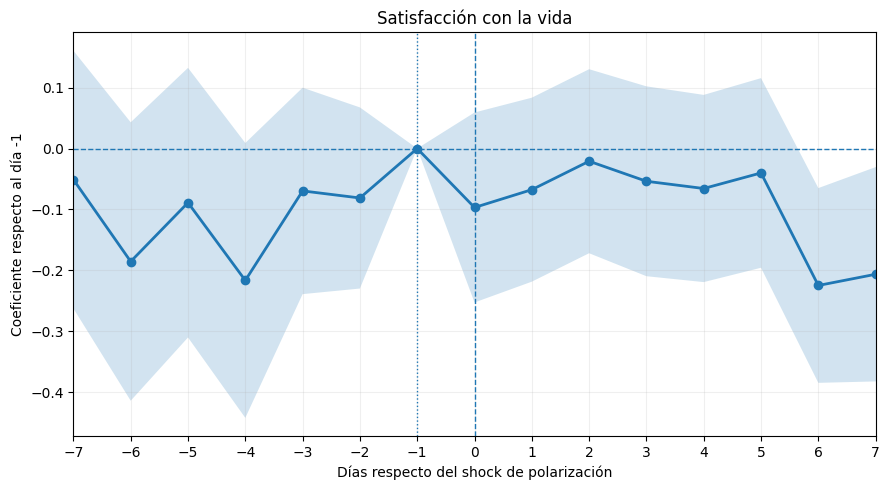

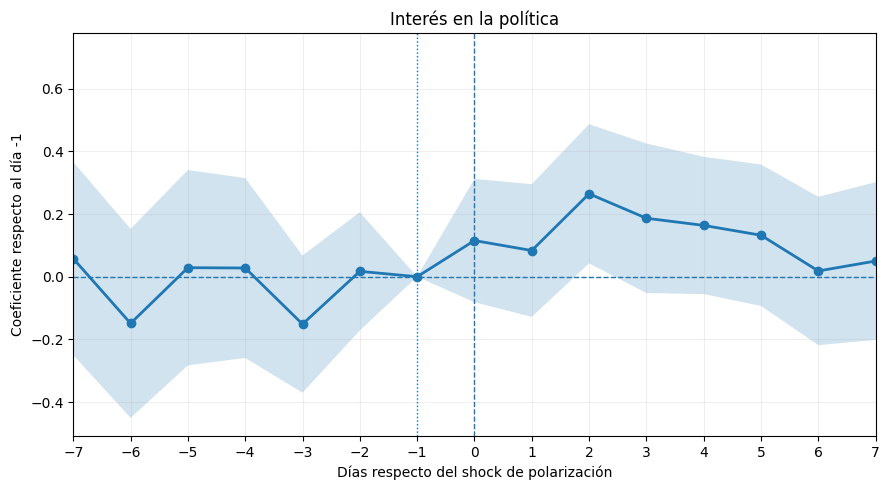

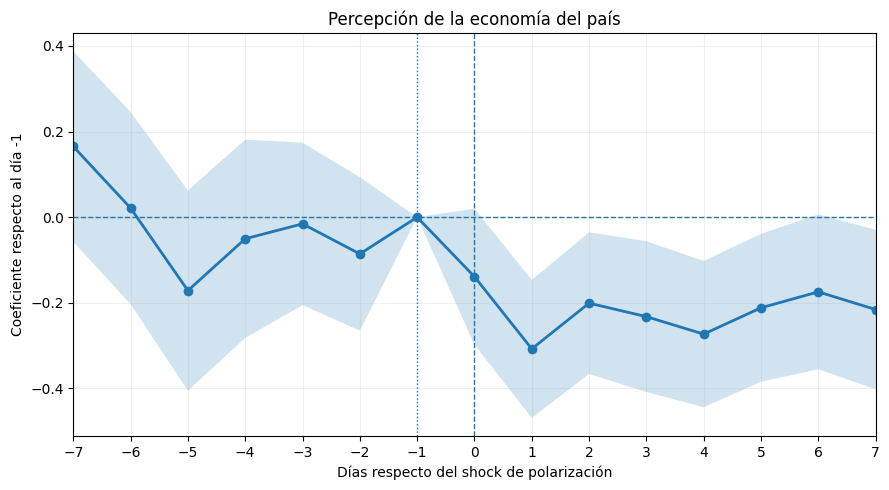

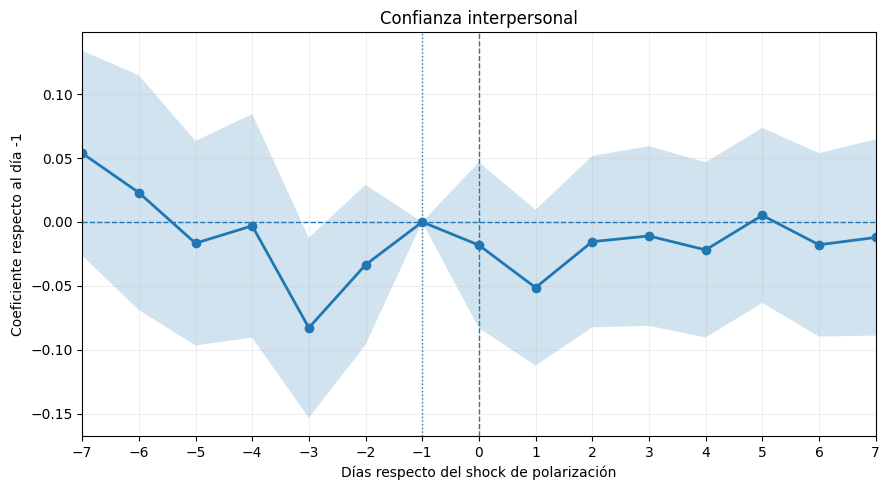

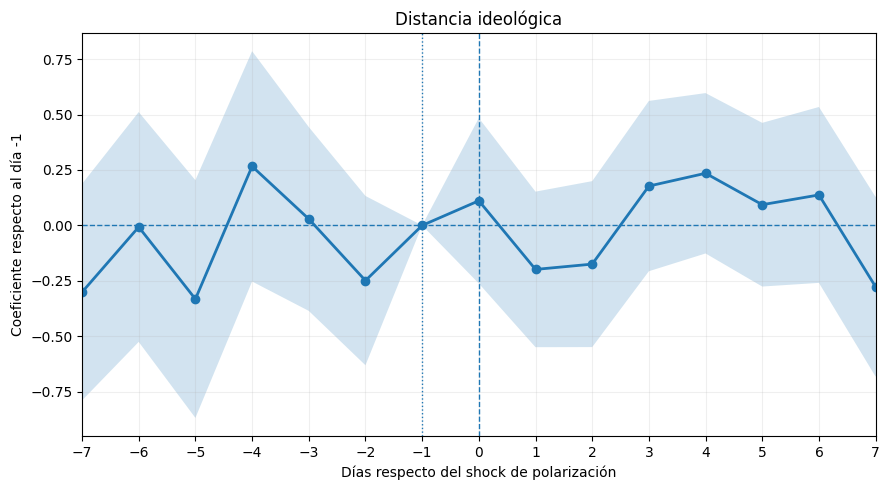

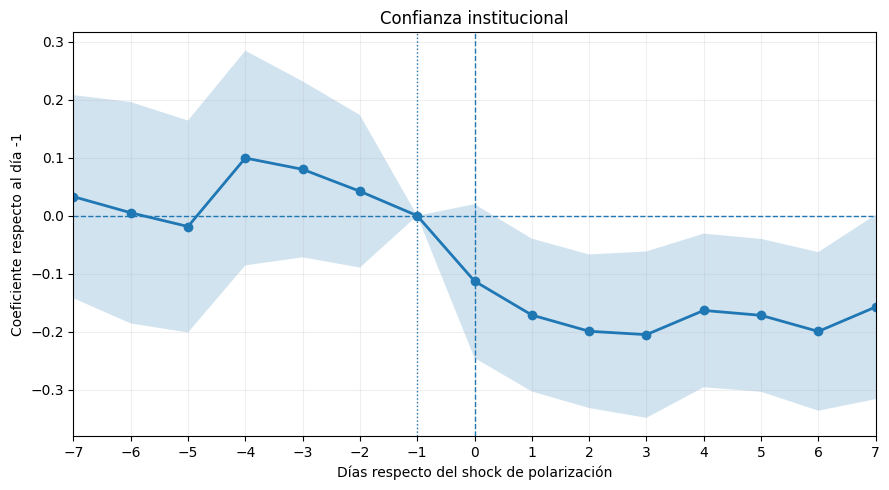

In [48]:
import matplotlib.pyplot as plt

# ============================================================
# GRÁFICOS DE TODAS LAS VARIABLES
# ============================================================

variables = [
    'life_satisfaction',
    'interest_politics',
    'econ_country',
    'trust_people',
    'left_right_distance',
    'confianza_institucional'
]

titulos = {
    'life_satisfaction': 'Satisfacción con la vida',
    'interest_politics': 'Interés en la política',
    'econ_country': 'Percepción de la economía del país',
    'trust_people': 'Confianza interpersonal',
    'left_right_distance': 'Distancia ideológica',
    'confianza_institucional': 'Confianza institucional'
}

for variable in variables:

    r = resultados_event_study[
        resultados_event_study['variable'] == variable
    ].copy()

    if len(r) == 0:
        continue

    plt.figure(figsize=(9, 5))

    # Intervalo de confianza
    plt.fill_between(
        r['dia'],
        r['ci_low'],
        r['ci_high'],
        alpha=0.20
    )

    # Coeficientes
    plt.plot(
        r['dia'],
        r['beta'],
        marker='o',
        linewidth=2
    )

    # Línea horizontal en cero
    plt.axhline(
        0,
        linestyle='--',
        linewidth=1
    )

    # Línea vertical en el día del shock
    plt.axvline(
        0,
        linestyle='--',
        linewidth=1
    )

    # Línea del período de referencia
    plt.axvline(
        -1,
        linestyle=':',
        linewidth=1
    )

    plt.title(
        titulos.get(variable, variable)
    )

    plt.xlabel(
        'Días respecto del shock de polarización'
    )

    plt.ylabel(
        'Coeficiente respecto al día -1'
    )

    plt.xticks(
        range(-7, 8)
    )

    plt.xlim(
        -7,
        7
    )

    plt.grid(
        alpha=0.2
    )

    plt.tight_layout()

    plt.show()